# Fundamentals of Data Science, Fall 2025
## Instructor: Dr. Khalaj
## HW 4 Part 1


In [ ]:
# Personal identifiers have been omitted from this public portfolio copy.
student_name = ""
student_id = ""
STUDENT_INFO = {'name': student_name, 'id': student_id}


# Variational Autoencoders (VAE)

## Overview
Welcome to the exciting world of Variational Autoencoders! VAEs are one of the most elegant generative models that combine the power of neural networks with probabilistic reasoning. Unlike traditional autoencoders that simply compress and decompress data, VAEs learn to generate new data by modeling the underlying probability distribution.

This homework will take you from theory to practice, implementing VAEs from scratch and applying them to real-world problems.

**Prerequisites - You should have a solid understanding of:**
- Variational inference and the Evidence Lower BOund (ELBO) objective
- Reparameterization trick for backpropagation through stochastic nodes
- KL divergence as a measure of distribution difference
- Backpropagation through stochastic (random) operations

## Mathematical Foundation

### The Core Problem
Given a dataset $\mathcal{D} = \{x_1, x_2, ..., x_N\}$, we want to learn the true data distribution $p(x)$. Instead of modeling $p(x)$ directly (often intractable), VAEs introduce a latent variable $z$ and model:
$$p(x) = \int p(x|z) p(z) dz$$

Where:
- $p(z)$ is the prior (typically $\mathcal{N}(0, I)$)
- $p(x|z)$ is the generative model (decoder)
- $q(z|x)$ is the approximate posterior (encoder)

### The ELBO Objective
We maximize the Evidence Lower BOund (ELBO):
$$\mathcal{L}_{ELBO} = \mathbb{E}_{q(z|x)}[\log p(x|z)] - D_{KL}(q(z|x) || p(z))$$

Breaking this down:
1. **Reconstruction Term**: $\mathbb{E}_{q(z|x)}[\log p(x|z)]$ - How well we can reconstruct data from latent codes
2. **Regularization Term**: $-D_{KL}(q(z|x) || p(z))$ - How close our latent distribution is to the prior

The KL divergence for two Gaussians has a closed form:
$$D_{KL}(\mathcal{N}(\mu, \sigma^2) || \mathcal{N}(0, 1)) = \frac{1}{2}\sum_{i=1}^{d} \left[\mu_i^2 + \sigma_i^2 - 1 - \log(\sigma_i^2)\right]$$

### The Reparameterization Trick
Since sampling $z \sim q(z|x)$ is not differentiable, we use:
$$z = \mu + \sigma \odot \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$

This allows gradients to flow through the stochastic node!

## Learning Objectives
1. Implement a VAE from scratch using PyTorch, understanding every mathematical detail
2. Master the trade-off between reconstruction fidelity and latent space structure (the $\beta$ parameter)
3. Apply VAEs to practical problems: image generation and anomaly detection
4. Experiment with advanced variants: β-VAE for disentanglement and Conditional VAE for controlled generation
5. Visualize and interpret latent spaces to understand what the model has learned


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


## Part 1: Building a Basic VAE (30 points)

### Task 1.1: Implement the VAE Architecture (15 points)

**The Architecture Puzzle**: A VAE consists of two neural networks working together like an artist and a critic:
- **The Encoder (Artist's Eye)**: Observes real data $x$ and infers what latent code $z$ likely generated it
- **The Decoder (Artist's Hand)**: Takes a latent code $z$ and tries to recreate data $\hat{x}$

**Mathematical Specification:**

The encoder learns $q_\phi(z|x)$, parameterized as:
$$q_\phi(z|x) = \mathcal{N}(z; \mu_\phi(x), \sigma_\phi^2(x) \cdot I)$$

Where:
- $\mu_\phi(x) = f_\mu(h_\phi(x))$ - neural network mapping input to latent mean
- $\log \sigma_\phi^2(x) = f_\sigma(h_\phi(x))$ - neural network mapping input to latent log-variance (we use log to ensure positivity)

The decoder learns $p_\theta(x|z)$, typically:
$$p_\theta(x|z) = \text{Bernoulli}(\text{sigmoid}(g_\theta(z))) \quad \text{or} \quad \mathcal{N}(x; g_\theta(z), \sigma^2 I)$$

**The Loss Function Breakdown:**

$$\mathcal{L}_{VAE} = \underbrace{-\mathbb{E}_{q(z|x)}[\log p(x|z)]}_{\text{Reconstruction Loss}} + \beta \cdot \underbrace{D_{KL}(q(z|x) || p(z))}_{\text{Regularization}}$$

**Reconstruction Loss** (for binary data like MNIST):
$$-\mathbb{E}_{q(z|x)}[\log p(x|z)] \approx -\frac{1}{L}\sum_{l=1}^{L} \sum_{i=1}^{D} [x_i \log \hat{x}_i + (1-x_i) \log(1-\hat{x}_i)]$$

Where $L$ is the number of samples (usually $L=1$ for efficiency).

**KL Divergence** (closed form for Gaussian):
$$D_{KL} = -\frac{1}{2}\sum_{i=1}^{d} \left[1 + \log(\sigma_i^2) - \mu_i^2 - \sigma_i^2\right]$$

**Your Implementation Tasks:**
1. **Encoder Network**: Maps $x \in \mathbb{R}^{784}$ → $h \in \mathbb{R}^{400}$ → $(\mu, \log\sigma^2) \in \mathbb{R}^{20}$
2. **Reparameterization**: Sample $z = \mu + \sigma \odot \epsilon$ where $\epsilon \sim \mathcal{N}(0,I)$
3. **Decoder Network**: Maps $z \in \mathbb{R}^{20}$ → $h \in \mathbb{R}^{400}$ → $\hat{x} \in [0,1]^{784}$
4. **Loss Computation**: Combine BCE reconstruction loss with KL divergence

**Implementation Requirements:**
- Use fully connected layers: `nn.Linear` for transformations
- Encoder: Shared layers → split into $\mu$ and $\log\sigma^2$ heads
- Decoder: Maps latent → hidden → output (with sigmoid for [0,1] range)
- Use ReLU activations for hidden layers
- Output sigmoid for binary reconstruction
- Use `torch.clamp(logvar, min=-10, max=10)` to prevent numerical explosions

**Why log variance?** Working with $\log\sigma^2$ instead of $\sigma^2$ ensures:
- No constraint violations ($\sigma^2 > 0$ automatically satisfied)
- Better numerical stability
- Unconstrained optimization

**Pro Tip**: The reparameterization trick is the key innovation that makes VAEs trainable!
$$z = \mu + \exp(0.5 \cdot \log\sigma^2) \odot \epsilon$$


In [2]:
# TODO: Implement the VAE class
# Fill in the missing parts marked with TODO

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20, beta=1.0):
        super(VAE, self).__init__()
        self.beta = beta
        
        # Encoder - shared layers
        self.encoder_fc = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        
        # Separate layers for mean and log variance
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid() 
        )
    
    def encode(self, x):
        h = self.encoder_fc(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
        raise NotImplementedError("Implement the reparameterize method")
    
    def reparameterize(self, mu, logvar):
        """Reparameterization trick: z = μ + σ ⊙ ε, where ε ~ N(0, I)"""

        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
        raise NotImplementedError("Implement the reparameterize method")
    
    def decode(self, z):
        """Decode latent code to reconstruction"""

        return self.decoder(z)
        raise NotImplementedError("Implement the decode method")
    
    def forward(self, x):
        """Forward pass: encode, reparameterize, decode, compute loss"""

        mu, logvar = self.encode(x.view(-1, x.shape[-1]))
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z)
        recon_loss = F.binary_cross_entropy(x_recon, x.view(-1, x.shape[-1]), reduction='sum')
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = (recon_loss + self.beta * kl_loss) / x.size(0) 
        
        return x_recon, mu, logvar, loss
        raise NotImplementedError("Implement the forward method")


### Task 1.2: Training the VAE on MNIST (10 points)

**Training Dynamics to Observe:**

During training, watch for the delicate balance:
- **Early Training**: Reconstruction loss dominates (model learns to copy inputs)
- **Mid Training**: KL term kicks in, forcing latent codes toward $\mathcal{N}(0,I)$
- **Late Training**: Equilibrium between reconstruction quality and latent structure

**The Training Recipe:**
1. **Data Preprocessing**: 
   - Normalize to [0,1] (MNIST pixels are already in this range)
   - Consider: Why not normalize to [-1,1]? (Hint: sigmoid output range)

2. **Loss Monitoring**:
   - Track reconstruction and KL terms separately
   - Watch for "KL collapse" (KL → 0, meaning $q(z|x) \approx p(z)$ - latent space becomes uninformative)
   - Watch for "Posterior collapse" (opposite problem - latent space ignored)

3. **Visualization Strategy**:
   - Every 5 epochs: Show original → reconstruction pairs
   - Generate random samples from prior $p(z) = \mathcal{N}(0,I)$
   - Plot loss curves: total, reconstruction, KL separately

**Key Hyperparameters:**
- Learning rate: Start with $10^{-3}$ (Adam optimizer)
- Batch size: 128 (good balance of gradient quality and speed)
- $\beta$: Start with 1.0 (we'll explore this in Part 2!)

**Success Metrics:**
- ✅ Reconstruction loss decreasing steadily
- ✅ KL divergence stabilizing (not vanishing!)
- ✅ Visual reconstructions recognizable as digits
- ✅ Generated samples diverse (not mode collapse)

**Fun Challenge**: Can you generate a digit that looks like a "7" but with the style of a "3"? This tests latent space interpolation!


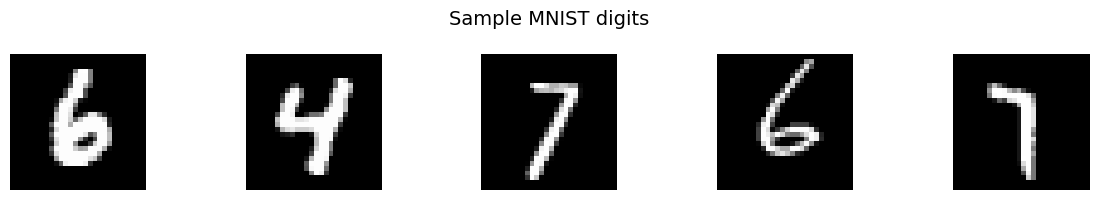

In [5]:
# Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    # TODO: Should we normalize? Why or why not?
    # It converts to [0,1]
    # We don`t normalize to [-1,1] because the decoder output uses sigmoid which is in range of [0,1]
])

# TODO: Load MNIST training and test datasets
# Hint: Use datasets.MNIST with appropriate parameters
train_dataset = datasets.MNIST(root='./data',train=True,download=True,transform=transform)
test_dataset = datasets.MNIST(root='./data',train=False,download=True,transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Visualize some samples
fig, axes = plt.subplots(1, 5, figsize=(12, 2))
for i, (img, _) in enumerate(train_loader):
    for j in range(5):
        axes[j].imshow(img[j].squeeze(), cmap='gray')
        axes[j].axis('off')
    break 
plt.suptitle('Sample MNIST digits', fontsize=14)
plt.tight_layout()
plt.show()


In [6]:
# TODO: Initialize model, optimizer, and loss function
# Model parameters: input_dim=784 (28x28), hidden_dim=400, latent_dim=20

model = VAE(input_dim=784, hidden_dim=400, latent_dim=20, beta=1.0)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
model = model.to(device)

def train_epoch(model, dataloader, optimizer, device):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    total_recon_loss = 0
    total_kl_loss = 0
    
    # TODO: Implement training loop for one epoch

    for x, _ in dataloader:
        x = x.to(device)
        x = x.view(x.size(0), -1)
        optimizer.zero_grad()

        # Forward pass
        x_recon, mu, logvar, loss = model(x)
        recon_loss = F.binary_cross_entropy(x_recon, x, reduction='sum') / x.size(0)
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)

        # Backward pass
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon_loss += recon_loss.item()
        total_kl_loss += kl_loss.item()
    return total_loss / len(dataloader), total_recon_loss / len(dataloader), total_kl_loss / len(dataloader)

def evaluate(model, dataloader, device):
    """Evaluate on test set"""
    model.eval()
    total_loss = 0
    total_recon_loss = 0
    total_kl_loss = 0
    
    with torch.no_grad():
        # TODO: Implement evaluation loop
        for x, _ in dataloader:
            x = x.to(device)
            x = x.view(x.size(0), -1)

            # Forward pass
            x_recon, mu, logvar, loss = model(x)
            recon_loss = F.binary_cross_entropy(x_recon, x, reduction='sum') / x.size(0)
            kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)

            total_loss += loss.item()
            total_recon_loss += recon_loss.item()
            total_kl_loss += kl_loss.item()
    
    return total_loss / len(dataloader), total_recon_loss / len(dataloader), total_kl_loss / len(dataloader)


Epoch 1/20:
  Train Loss: 177.3663 (Recon: 170.2271, KL: 7.1391)
  Test Loss: 138.3091 (Recon: 170.2271, KL: 12.9569)
Epoch 2/20:
  Train Loss: 128.7660 (Recon: 114.4058, KL: 14.3602)
  Test Loss: 120.5663 (Recon: 114.4058, KL: 15.6275)
Epoch 3/20:
  Train Loss: 118.6336 (Recon: 102.8136, KL: 15.8201)
  Test Loss: 115.1840 (Recon: 102.8136, KL: 16.1667)
Epoch 4/20:
  Train Loss: 114.4865 (Recon: 98.0190, KL: 16.4675)
  Test Loss: 111.8408 (Recon: 98.0190, KL: 17.3005)
Epoch 5/20:
  Train Loss: 111.4414 (Recon: 94.0440, KL: 17.3974)
  Test Loss: 109.4499 (Recon: 94.0440, KL: 17.6753)


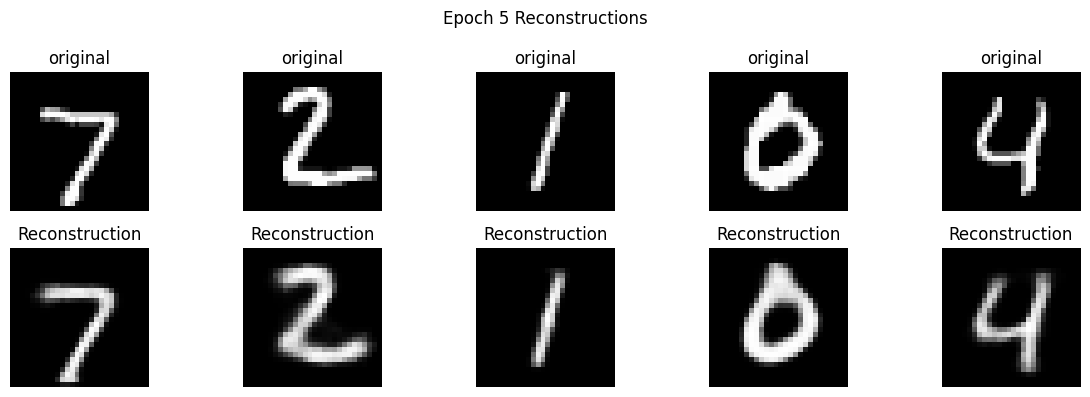

Epoch 6/20:
  Train Loss: 109.1512 (Recon: 91.2007, KL: 17.9505)
  Test Loss: 107.5939 (Recon: 91.2007, KL: 18.3697)
Epoch 7/20:
  Train Loss: 107.6047 (Recon: 89.3392, KL: 18.2655)
  Test Loss: 106.5089 (Recon: 89.3392, KL: 18.0430)
Epoch 8/20:
  Train Loss: 106.4152 (Recon: 87.9182, KL: 18.4969)
  Test Loss: 105.5819 (Recon: 87.9182, KL: 18.5204)
Epoch 9/20:
  Train Loss: 105.3960 (Recon: 86.6903, KL: 18.7056)
  Test Loss: 104.5922 (Recon: 86.6903, KL: 18.7632)
Epoch 10/20:
  Train Loss: 104.5219 (Recon: 85.6262, KL: 18.8958)
  Test Loss: 104.0706 (Recon: 85.6262, KL: 18.9861)


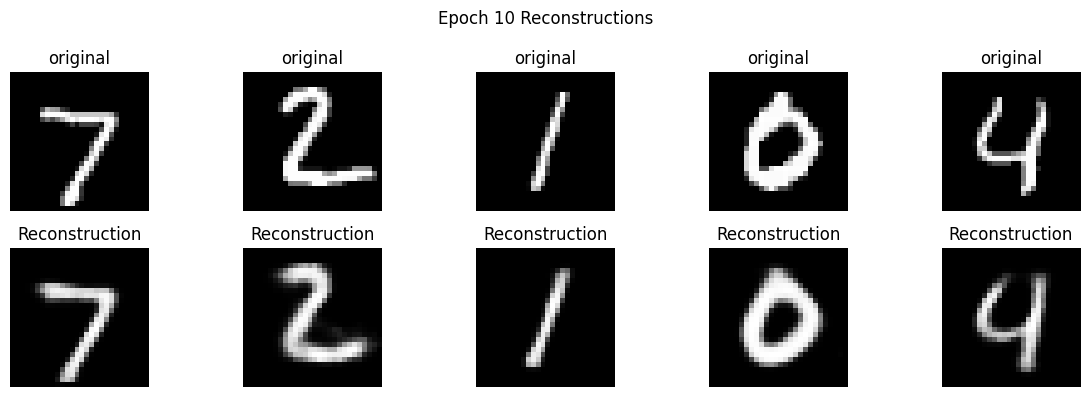

Epoch 11/20:
  Train Loss: 103.8404 (Recon: 84.8399, KL: 19.0005)
  Test Loss: 103.4046 (Recon: 84.8399, KL: 19.1820)
Epoch 12/20:
  Train Loss: 103.2595 (Recon: 84.1743, KL: 19.0852)
  Test Loss: 102.8665 (Recon: 84.1743, KL: 19.3584)
Epoch 13/20:
  Train Loss: 102.7481 (Recon: 83.5684, KL: 19.1798)
  Test Loss: 102.6573 (Recon: 83.5684, KL: 19.2196)
Epoch 14/20:
  Train Loss: 102.3793 (Recon: 83.1337, KL: 19.2456)
  Test Loss: 102.4865 (Recon: 83.1337, KL: 19.3947)
Epoch 15/20:
  Train Loss: 101.9425 (Recon: 82.6387, KL: 19.3038)
  Test Loss: 102.1367 (Recon: 82.6387, KL: 19.3163)


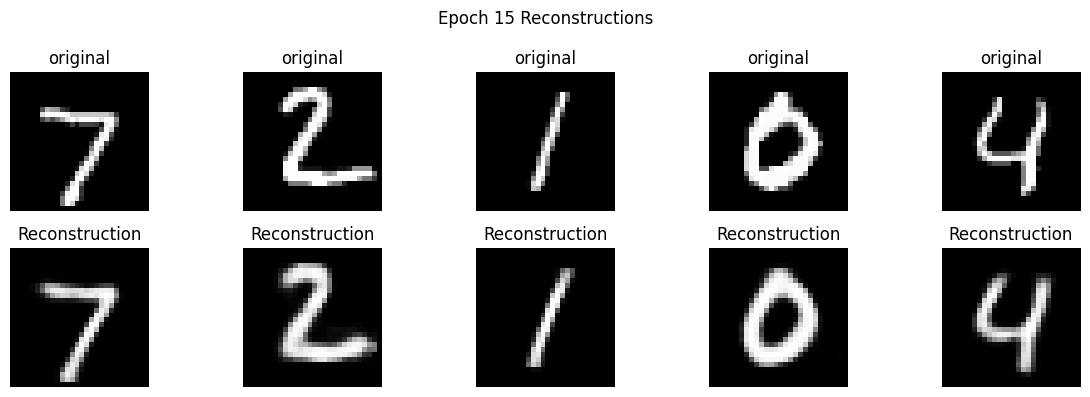

Epoch 16/20:
  Train Loss: 101.6045 (Recon: 82.2765, KL: 19.3280)
  Test Loss: 101.6798 (Recon: 82.2765, KL: 19.0405)
Epoch 17/20:
  Train Loss: 101.3491 (Recon: 81.9507, KL: 19.3984)
  Test Loss: 101.7815 (Recon: 81.9507, KL: 19.2187)
Epoch 18/20:
  Train Loss: 101.0786 (Recon: 81.6273, KL: 19.4513)
  Test Loss: 101.5908 (Recon: 81.6273, KL: 19.7716)
Epoch 19/20:
  Train Loss: 100.8687 (Recon: 81.3612, KL: 19.5075)
  Test Loss: 101.2557 (Recon: 81.3612, KL: 19.4914)
Epoch 20/20:
  Train Loss: 100.6151 (Recon: 81.0793, KL: 19.5358)
  Test Loss: 101.0820 (Recon: 81.0793, KL: 19.4720)


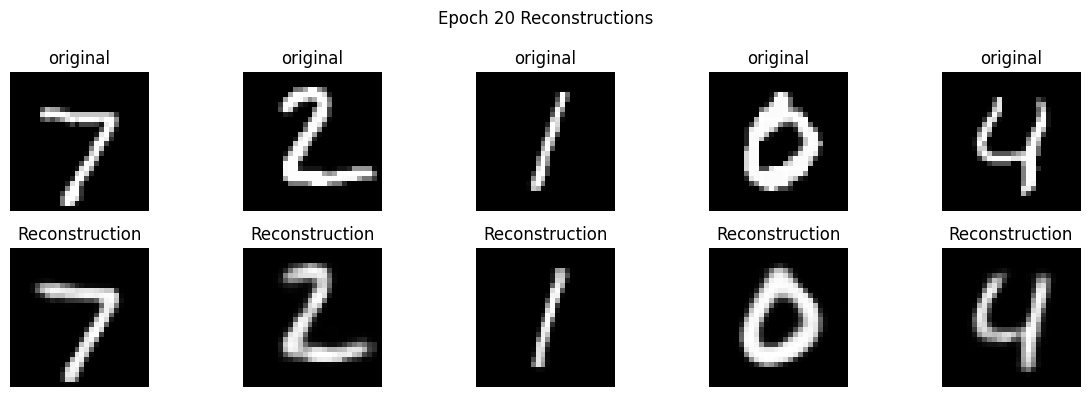

In [7]:
# Training loop
num_epochs = 20
train_losses, train_recon_losses, train_kl_losses = [], [], []
test_losses, test_recon_losses, test_kl_losses = [], [], []

for epoch in range(num_epochs):
    # TODO: Call training and evaluation functions
    train_loss, train_recon, train_kl = train_epoch(model, train_loader, optimizer, device)
    test_loss, test_recon, test_kl = evaluate(model, test_loader, device)
    
    # Store losses
    train_losses.append(train_loss)
    train_recon_losses.append(train_recon)
    train_kl_losses.append(train_kl)
    test_losses.append(test_loss)
    test_recon_losses.append(test_recon)
    test_kl_losses.append(test_kl)
    
    print(f'Epoch {epoch+1}/{num_epochs}:')
    print(f'  Train Loss: {train_loss:.4f} (Recon: {train_recon:.4f}, KL: {train_kl:.4f})')
    print(f'  Test Loss: {test_loss:.4f} (Recon: {train_recon:.4f}, KL: {test_kl:.4f})')
    
    # Visualize reconstructions every 5 epochs
    if (epoch + 1) % 5 == 0:
        model.eval()
        with torch.no_grad():
            # TODO: Get a batch of test images
            # Reconstruct them and visualize side-by-side with originals
            x, _ = next(iter(test_loader))
            x = x.to(device)
            x_f = x.view(x.size(0), -1)
            x_recon, _, _, _ = model(x_f)

            # Plot
            fig, axes = plt.subplots(2, 5, figsize=(12, 4))
            for i in range(5):
                axes[0, i].imshow(x[i].squeeze().cpu(), cmap='gray')
                axes[0, i].set_title("original")
                axes[0, i].axis('off')

                axes[1, i].imshow(x_recon[i].view(28, 28).cpu(), cmap='gray')
                axes[1, i].set_title("Reconstruction")
                axes[1, i].axis('off')

            plt.suptitle(f'Epoch {epoch+1} Reconstructions')
            plt.tight_layout()
            plt.show()

            pass


### Task 1.3: Latent Space Exploration (5 points)

**The Latent Space Adventure**: Think of the latent space as a "map" of all possible digits. Each point in this 20-dimensional space corresponds to a unique digit. Let's explore this hidden world!

**1. Latent Space Visualization**

**Theory**: The encoder learns a mapping $f: \mathcal{X} \rightarrow \mathcal{Z}$ where $\mathcal{Z} \subset \mathbb{R}^{20}$ is the latent space. We want to understand the structure of this space.

**PCA Visualization**:
- Encode all test images: $\{z_i = \mu_\phi(x_i)\}_{i=1}^{N}$
- Apply PCA: Project to 2D for visualization: $\tilde{z}_i = W_{PCA}^T z_i$ where $W_{PCA} \in \mathbb{R}^{20 \times 2}$
- Color by digit class
- **Question**: Do similar digits cluster? What does this tell us about the learned representation?

**Mathematical Insight**: If digits cluster by class in latent space, the VAE has learned semantically meaningful features. The latent space acts like a "feature extractor" that captures digit identity.

**2. Prior Sampling (Generative Mode)**

**Theory**: To generate new data, we:
1. Sample $z \sim p(z) = \mathcal{N}(0, I)$ (the prior)
2. Decode: $\hat{x} = g_\theta(z)$

**Why this works**: If $q(z|x)$ is well-matched to $p(z)$, sampling from the prior should generate realistic data!

**Implementation**: Sample $z \sim \mathcal{N}(0, I)$, decode, and visualize a grid of generated digits.

**3. Latent Space Interpolation**

**The Magic Formula**: Given two latent codes $z_1$ and $z_2$:
$$z(\alpha) = (1-\alpha)z_1 + \alpha z_2, \quad \alpha \in [0,1]$$

Then decode: $x(\alpha) = g_\theta(z(\alpha))$

**Why This Works**: If the latent space is well-structured (regularized by KL divergence), linear interpolation in latent space should correspond to smooth semantic interpolation!

**Analysis Questions**:
1. **Clustering**: Are digits of the same class near each other in latent space?
   - Mathematical test: Compute average pairwise distance within classes vs. between classes
   
2. **Interpolation Smoothness**: When interpolating 0 → 9, do you see:
   - Smooth transitions (good!)
   - Abrupt jumps (latent space not smooth)
   - Meaningful intermediate digits (e.g., 0 → 8 → 9)?

3. **Manifold Hypothesis**: The data likely lies on a lower-dimensional manifold. Can you estimate the intrinsic dimensionality?

**Fun Experiment**: Try interpolating between two "7"s. Do you get different styles of 7s, or does it stay the same? This tests intra-class diversity!


1. Clustering: If training works well similar digits are nearby points in latent space and Latent space captures digit identity. 

2. Interpolation Smoothness: If training works well we have smooth movement in latent space which means smooth change in digit

3. Manifold Hypothesis: Data lives on a much lower-dimensional manifold even though latent_dim = 20, effective dimension is smaller.

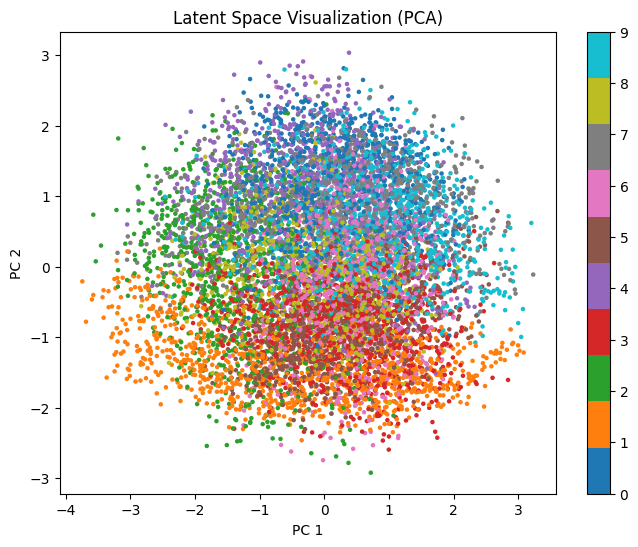

In [8]:
# TODO: Visualize latent space
# 1. Encode a subset of test images
# 2. Apply PCA to reduce to 2D (or use t-SNE for better visualization)
# 3. Color points by their true labels
# 4. Plot the 2D visualization

# Hint: Use model.encode() to get latent representations
# Then use sklearn.decomposition.PCA for dimensionality reduction

from sklearn.decomposition import PCA
import numpy as np

model.eval()

latents = []
labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        x = x.view(x.size(0), -1)

        mu, logvar = model.encode(x)
        latents.append(mu.cpu())
        labels.append(y)

latents = torch.cat(latents, dim=0).numpy()
labels = torch.cat(labels, dim=0).numpy()

pca = PCA(n_components=2)
latents_2d = pca.fit_transform(latents)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latents_2d[:, 0],
    latents_2d[:, 1],
    c=labels,
    cmap='tab10',
    s=5
)
plt.colorbar(scatter)
plt.title("Latent Space Visualization (PCA)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()


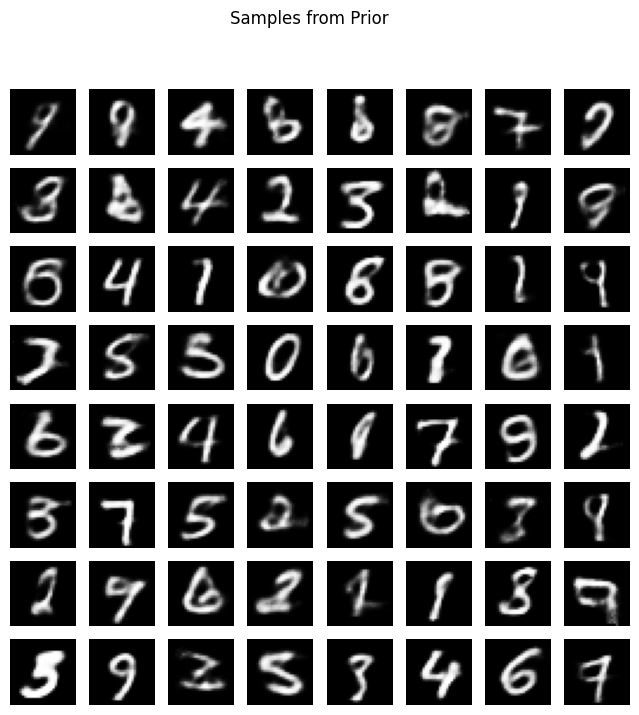

In [9]:
# TODO: Generate new samples from prior
# Sample z ~ N(0, I) and decode to generate new images
# Display a grid of generated images

num_samples = 64
model.eval()
with torch.no_grad():
    # TODO: Sample from prior and generate images
    z = torch.randn(num_samples, 20).to(device)
    samples = model.decode(z)
    samples = samples.view(-1, 28, 28).cpu()
    pass

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for i in range(8):
    for j in range(8):
        idx = i * 8 + j
        axes[i, j].imshow(samples[idx], cmap='gray')
        axes[i, j].axis('off')

plt.suptitle("Samples from Prior")
plt.show()


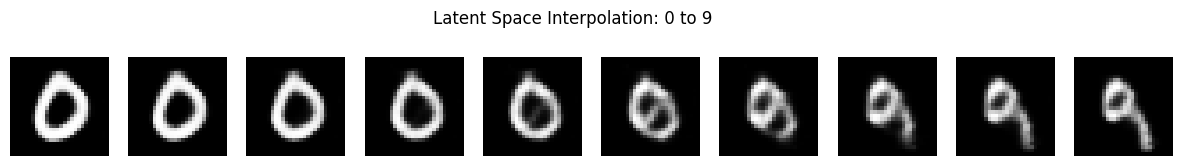

In [13]:
# TODO: Latent space interpolation
# 1. Select two images from different classes (e.g., digit 0 and digit 9)
# 2. Encode both to get z1 and z2
# 3. Interpolate: z_interp = α * z1 + (1 - α) * z2, for α in [0, 1]
# 4. Decode interpolated codes and visualize the sequence

x, y = next(iter(test_loader))

idx0 = (y == 0).nonzero()[0].item()
idx9 = (y == 9).nonzero()[0].item()

x0 = x[idx0].view(1, -1).to(device)
x9 = x[idx9].view(1, -1).to(device)

model.eval()
with torch.no_grad():
    # TODO: Implement interpolation
    z0, _ = model.encode(x0)
    z9, _ = model.encode(x9)

alphas = torch.linspace(0, 1, steps=10).to(device)
z_interp = [(1 - a) * z0 + a * z9 for a in alphas]
z_interp = torch.cat(z_interp, dim=0)

with torch.no_grad():
    interp_imgs = model.decode(z_interp)
    interp_imgs = interp_imgs.view(-1, 28, 28).cpu()
    pass

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(interp_imgs[i], cmap='gray')
    axes[i].axis('off')

plt.suptitle("Latent Space Interpolation: 0 to 9")
plt.show()


## Part 2: β-VAE and KL Divergence Trade-off (25 points)

**The Fundamental Tension**: There's a natural trade-off in VAEs between:
- **Reconstruction Quality**: How well we can recreate the input
- **Latent Structure**: How well-organized the latent space is

This is captured by the $\beta$-VAE objective:
$$\mathcal{L}_{\beta\text{-VAE}} = -\mathbb{E}_{q(z|x)}[\log p(x|z)] + \beta \cdot D_{KL}(q(z|x) || p(z))$$

### Task 2.1: Implement β-VAE (10 points)

**The β Parameter - A Dial for Disentanglement**

**Theory**: By controlling $\beta$, we control the strength of the KL regularization:

- **$\beta < 1$** (e.g., 0.1, 0.5): Weak regularization
  - Latent codes can deviate more from $\mathcal{N}(0,I)$
  - Better reconstruction (model uses latent space freely)
  - Risk: Latent space may not be smooth/generative
  
- **$\beta = 1$**: Standard VAE (balanced)
  - Theoretical justification: True ELBO (when $\beta=1$)
  - Good balance between reconstruction and regularization

- **$\beta > 1$** (e.g., 2, 5, 10): Strong regularization  
  - Forces $q(z|x) \approx p(z) = \mathcal{N}(0,I)$ more strongly
  - Promotes disentangled representations (each dimension controls independent factors)
  - Risk: Reconstruction quality may suffer

**The Disentanglement Hypothesis**: 
When $\beta > 1$, the model is incentivized to encode information more efficiently. This often leads to **disentanglement** - each latent dimension controls a single, interpretable factor of variation (e.g., digit rotation, stroke width, style).

**Mathematical Intuition**: 
Higher $\beta$ means we penalize "wasting" latent dimensions. The model must pack information efficiently, leading to independent factors.

**Implementation Strategy**:
1. Modify your VAE to accept $\beta$ as a parameter
2. Train separate models for each $\beta \in \{0.1, 0.5, 1.0, 2.0, 5.0, 10.0\}$
3. For each model, track:
   - Final reconstruction loss (per pixel)
   - Final KL divergence
   - Visual reconstruction quality
   - Sample diversity (generate 100 samples, count unique digit types)

**Expected Observations**:
- **Reconstruction Loss**: Should increase as $\beta$ increases (harder to reconstruct with constrained latent)
- **KL Divergence**: Should decrease as $\beta$ increases (stronger penalty)
- **Sample Quality**: At $\beta=1$, good balance. At very high $\beta$, may see "fuzzier" reconstructions

**Key Question**: Can you find a "sweet spot" $\beta$ that maximizes both reconstruction quality AND disentanglement? This is an active research area!



Training β-VAE with β=0.1


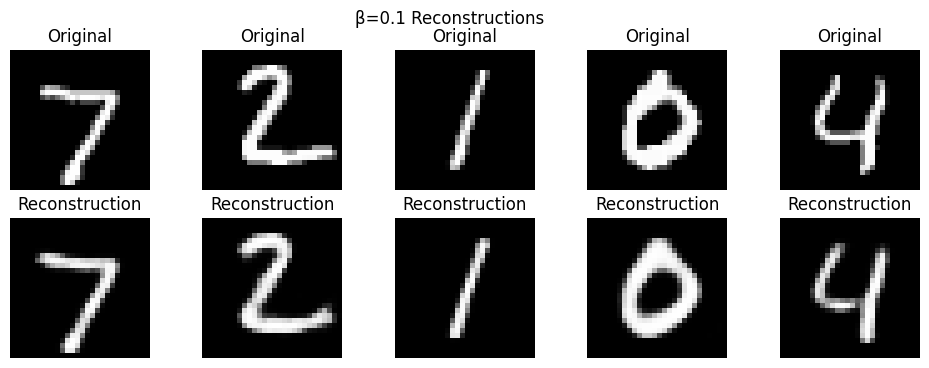

β=0.1 -> Recon per pixel: 0.0826, KL: 53.2650

Training β-VAE with β=0.5


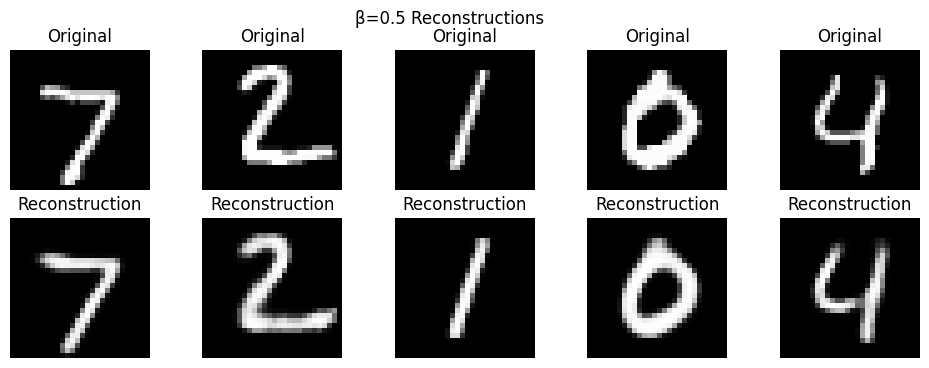

β=0.5 -> Recon per pixel: 0.0937, KL: 27.7202

Training β-VAE with β=1.0


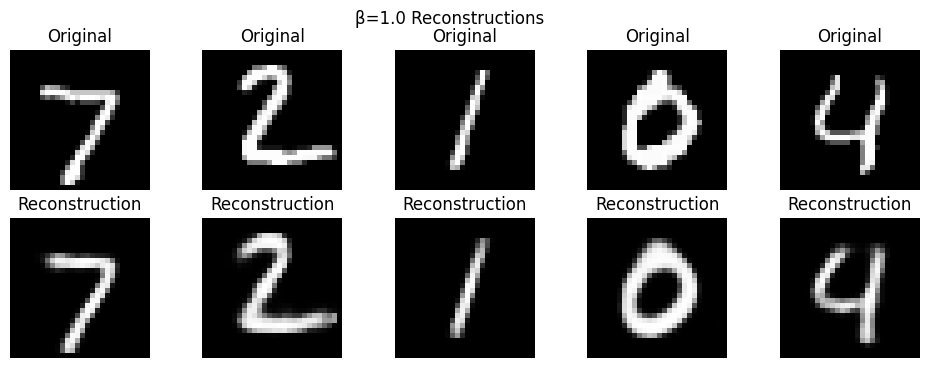

β=1.0 -> Recon per pixel: 0.1017, KL: 20.3988

Training β-VAE with β=2.0


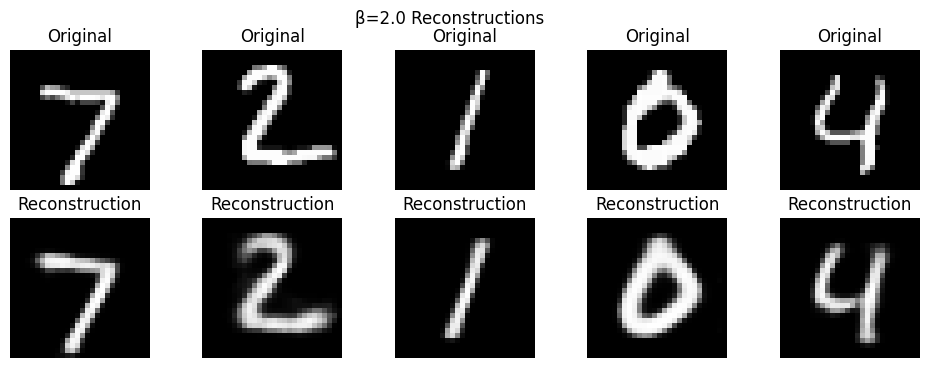

β=2.0 -> Recon per pixel: 0.1169, KL: 13.6849

Training β-VAE with β=5.0


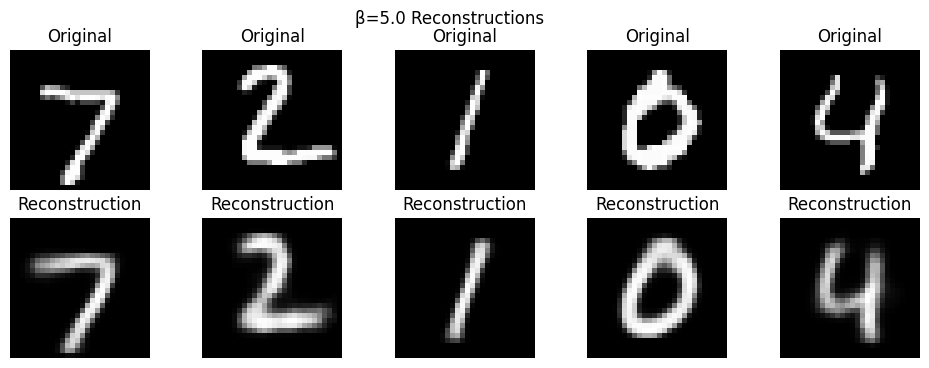

β=5.0 -> Recon per pixel: 0.1488, KL: 7.1798

Training β-VAE with β=10.0


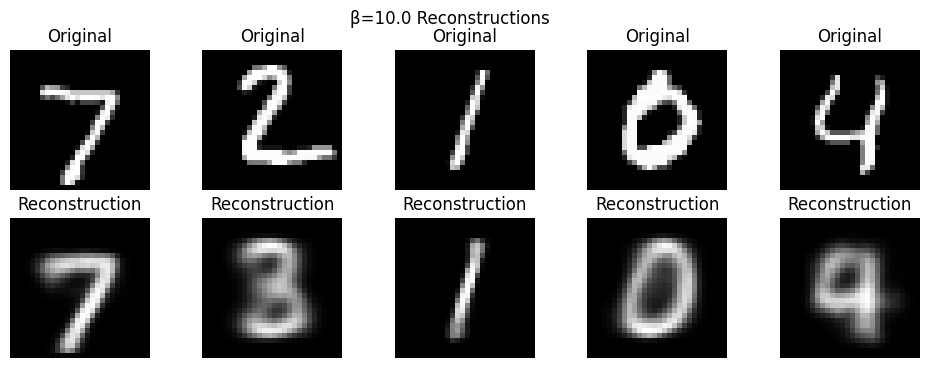

β=10.0 -> Recon per pixel: 0.1903, KL: 3.2556


In [14]:
# TODO: Modify your VAE to support β parameter
# You can either:
# 1. Add β as a parameter to the __init__ method, OR
# 2. Pass β to the forward method

# Then train models with different β values and compare:
# - Final reconstruction quality
# - KL divergence values (should decrease with lower β)
# - Latent space structure (use PCA visualization)
# - Sample quality

import matplotlib.pyplot as plt

betas = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
results = {}
num_epochs = 20
latent_dim = 20
num_samples = 100

for beta in betas:

    print(f"\nTraining β-VAE with β={beta}")
    model = VAE(input_dim=784, hidden_dim=400, latent_dim=latent_dim, beta=beta).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    # Train
    for epoch in range(num_epochs):
        train_epoch(model, train_loader, optimizer, device)

    test_loss, test_recon, test_kl = evaluate(model, test_loader, device)
    # per-pixel reconstruction
    recon_per_pixel = test_recon / 784 

    results[beta] = {
        "model": model,
        "recon_per_pixel": recon_per_pixel,
        "kl": test_kl
    }

    model.eval()
    with torch.no_grad():
        x, _ = next(iter(test_loader))
        x = x[:5].to(device)
        x_flat = x.view(x.size(0), -1)
        x_recon, _, _, _ = model(x_flat)

        fig, axes = plt.subplots(2, 5, figsize=(12, 4))
        for i in range(5):
            axes[0, i].imshow(x[i].cpu().squeeze(), cmap='gray')
            axes[0, i].set_title("Original")
            axes[0, i].axis('off')

            axes[1, i].imshow(x_recon[i].view(28,28).cpu(), cmap='gray')
            axes[1, i].set_title("Reconstruction")
            axes[1, i].axis('off')
        plt.suptitle(f"β={beta} Reconstructions")
        plt.show()

    with torch.no_grad():
        z = torch.randn(num_samples, latent_dim).to(device)
        samples = model.decode(z).view(-1, 28, 28).cpu()

    results[beta]["samples"] = samples
    print(f"β={beta} -> Recon per pixel: {recon_per_pixel:.4f}, KL: {test_kl:.4f}")




### Task 2.2: Disentangled Representations (15 points)

**What is Disentanglement?** 
A disentangled representation is one where each latent dimension corresponds to exactly one underlying factor of variation. For example:
- Dimension 1 controls digit rotation
- Dimension 2 controls stroke thickness  
- Dimension 3 controls digit width

This makes the model **interpretable** and **controllable** - you can manipulate specific attributes independently!

**The Latent Traversal Experiment**

**Mathematical Setup**: For dimension $j$, we fix all other dimensions and vary only $z_j$:

$$z^{(j)}(t) = [0, ..., 0, t, 0, ..., 0]^T, \quad t \in [-3, 3]$$

Then decode: $x^{(j)}(t) = g_\theta(z^{(j)}(t))$

**Why $\pm 3$?** Under the prior $p(z) = \mathcal{N}(0,I)$, about 99.7% of the probability mass lies within $[-3, 3]$. Traversing this range explores the "typical" latent space.

**What to Look For**:

1. **Disentangled Dimension** (ideal):
   - Varying $z_j$ changes ONE clear property
   - Example: Only rotation changes, nothing else
   - Smooth, continuous changes

2. **Entangled Dimension** (undesirable):
   - Varying $z_j$ changes multiple properties simultaneously
   - Example: Both rotation AND thickness change together
   - Hard to interpret

3. **Dead Dimension** (waste):
   - Varying $z_j$ has no visible effect
   - The model isn't using this dimension
   - Suggests over-parameterization

**Implementation Strategy**:

```python
# For each dimension j in [0, latent_dim-1]:
z_base = torch.zeros(1, latent_dim)  # Start at origin
traversal_values = torch.linspace(-3, 3, steps=11)
images = []
for t in traversal_values:
    z = z_base.clone()
    z[0, j] = t  # Vary only dimension j
    x_gen = decoder(z)
    images.append(x_gen)
# Visualize the row of images
```

**Quantitative Metrics** (Optional but Impressive):

**Mutual Information Gap (MIG)**: Measures how much information each ground-truth factor shares with each latent dimension. Higher MIG = better disentanglement.

For MNIST, ground-truth factors might be: digit class, rotation, thickness, etc. (if you have annotations). Without annotations, visual inspection is the standard approach.

**Visualization Tips**:
- Create a grid: rows = latent dimensions, columns = traversal steps
- This creates a "latent space atlas" showing what each dimension does
- Label dimensions: "Controls rotation", "Controls thickness", etc.

**Analysis Questions**:

1. **Optimal β**: Which $\beta$ produces the clearest disentanglement? Why?
   - Tip: Compare traversal grids across different $\beta$ values

2. **Dimension Analysis**: Can you identify what each dimension controls?
   - Some dimensions might control: rotation, thickness, style, shape variations
   - Create a "dimension dictionary" mapping $z_j$ → semantic meaning

3. **Trade-offs**: 
   - At high $\beta$, you might see clearer disentanglement but blurrier reconstructions
   - Is there a $\beta$ that gives good disentanglement without sacrificing too much quality?
   - How does this compare to $\beta=1$ (standard VAE)?

**Fun Challenge**: Try to create a "digit morphing" video by smoothly interpolating through latent space along the dimension that controls style. This is how generative models are used in animation!


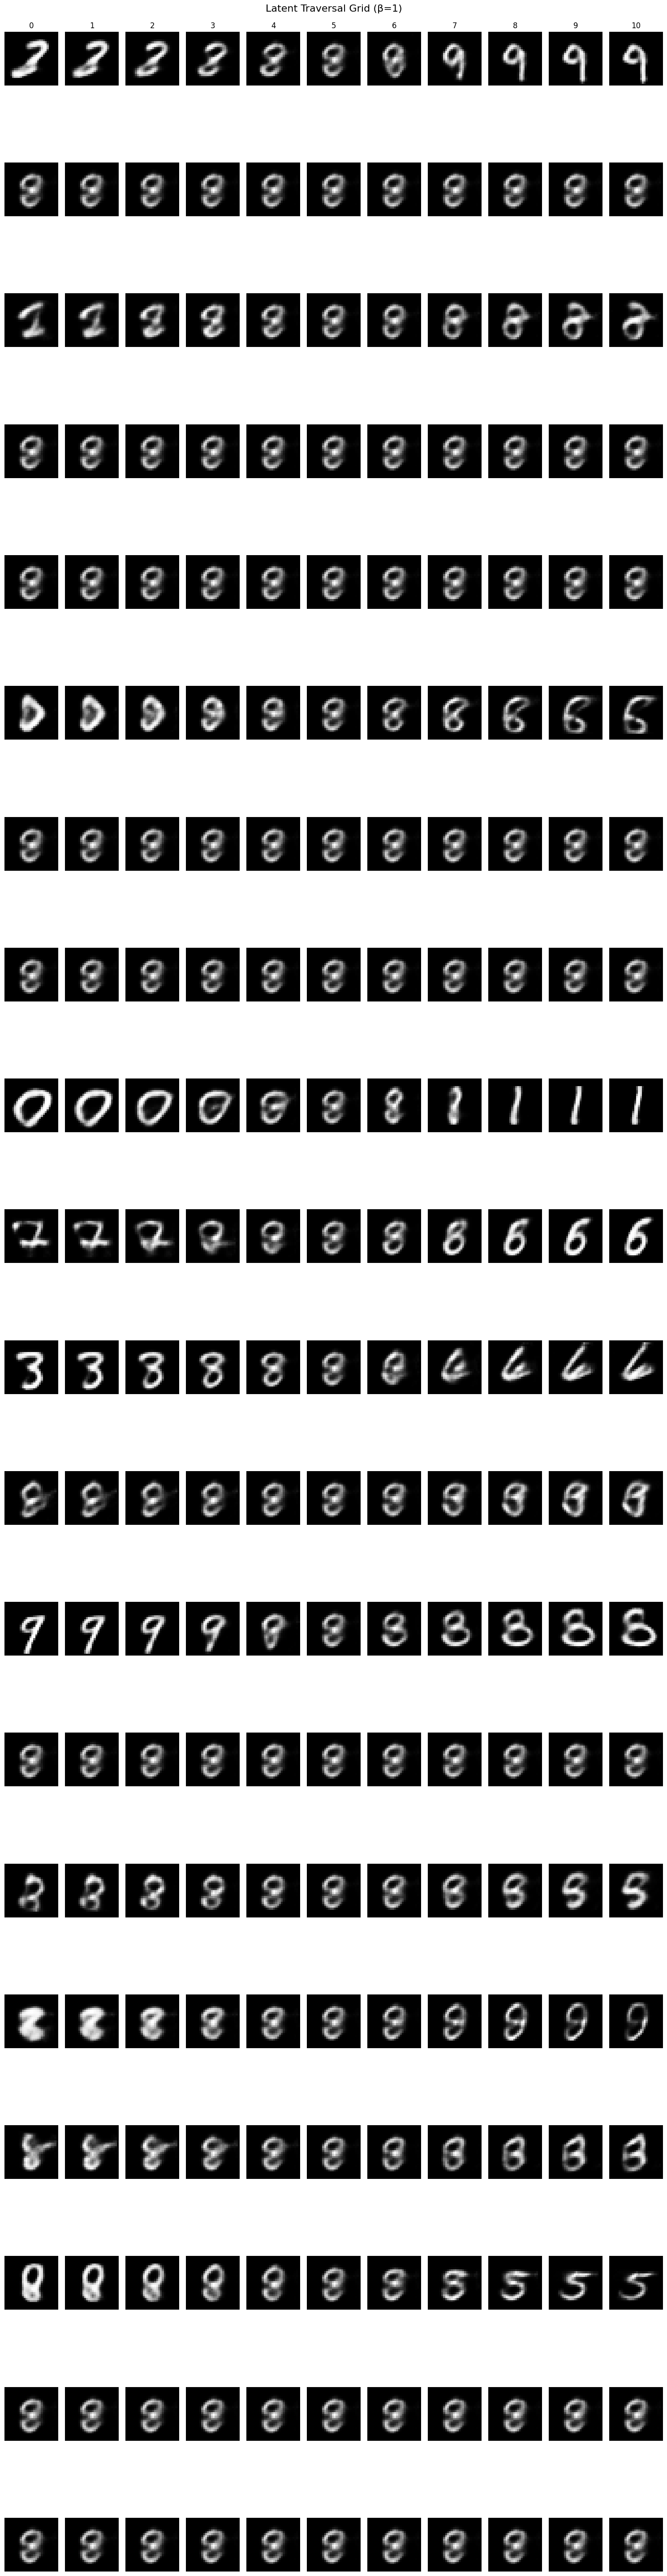

In [16]:
# TODO: Implement latent traversal
# For a trained β-VAE model (choose best β from previous experiment):

def latent_traversal(model, dim, num_steps=10, z_base=None, device='cpu'):
    """
    Traverse one latent dimension while keeping others fixed.
    
    Args:
        model: Trained VAE model
        dim: Dimension to traverse (0 to latent_dim-1)
        num_steps: Number of steps in traversal
        z_base: Base latent code (if None, use zero vector)
        device: Device to run on
    
    Returns:
        Generated images as numpy array
    """
    model.eval()
    with torch.no_grad():
        # TODO: Implement traversal
        # Create z_base if not provided
        # Vary z_base[dim] from -3 to 3
        # Decode each z and return images

        latent_dim = model.fc_mu.out_features  

        if z_base is None:
            z_base = torch.zeros(1, latent_dim).to(device)
        else:
            z_base = z_base.clone().to(device)

        traversal_values = torch.linspace(-3, 3, num_steps).to(device)

        images = []
        for val in traversal_values:
            z = z_base.clone()
            z[0, dim] = val 
            x_decoded = model.decode(z).view(28, 28).cpu().numpy()
            images.append(x_decoded)

    return np.array(images)
    
    pass

# Visualize traversals for all latent dimensions
latent_dim = 20  # Adjust based on your model
best_beta = 1  # for example, replace with the actual best
model = results[best_beta]["model"]
z_base = torch.zeros(1, latent_dim).to(device)
fig, axes = plt.subplots(latent_dim, 11, figsize=(15, 3*latent_dim))
# TODO: Create visualization grid showing traversals
for d in range(latent_dim):
    imgs = latent_traversal(model, dim=d, num_steps=11, z_base=z_base, device=device)
    for i in range(11):
        axes[d, i].imshow(imgs[i], cmap='gray')
        axes[d, i].axis('off')
        if d == 0:
            axes[d, i].set_title(f"{i}")  

plt.suptitle(f"Latent Traversal Grid (β={best_beta})", fontsize=16)
plt.tight_layout()
plt.show()


Rows 20 , 19, 14, 8, 7, 5, 4, 2 are  **Dead Dimensions** . It means varying $z_j$ has no visible effect and the model isn't using these dimensions.

Row 17 is for roation and is **Distangled** Dimension.

Some rows both change the rotation and also the number so they are **Entangled** like rows 1 and 3.


## Part 3: Conditional VAE (CVAE) (20 points) 

**The Power of Control**: Standard VAEs are like an artist who creates random artwork. Conditional VAEs are like an artist who can create exactly what you ask for: "Draw me a cat" or "Generate a picture of a sunset over mountains."

### Task 3.1: Implement Conditional VAE (15 points)

**Mathematical Foundation**

Standard VAE models $p(x)$. CVAE models $p(x|y)$ where $y$ is a condition (e.g., class label).

**The CVAE Objective**:
$$\mathcal{L}_{CVAE} = -\mathbb{E}_{q(z|x,y)}[\log p(x|z,y)] + \beta \cdot D_{KL}(q(z|x,y) || p(z|y))$$

Typically, we use $p(z|y) = p(z) = \mathcal{N}(0,I)$ (prior doesn't depend on condition), so:
$$\mathcal{L}_{CVAE} = -\mathbb{E}_{q(z|x,y)}[\log p(x|z,y)] + \beta \cdot D_{KL}(q(z|x,y) || \mathcal{N}(0,I))$$

**Key Architectural Changes**:

1. **Encoder**: $q_\phi(z|x,y)$
   - Input: Concatenate $[x, y_{one-hot}]$
   - Output: $(\mu, \log\sigma^2)$
   - Implementation: `torch.cat([x_flattened, one_hot(y)], dim=1)`

2. **Decoder**: $p_\theta(x|z,y)$
   - Input: Concatenate $[z, y_{one-hot}]$  
   - Output: $\hat{x}$
   - Implementation: `torch.cat([z, one_hot(y)], dim=1)`

**Why This Works**:
By conditioning both encoder and decoder on $y$, the model learns:
- Encoder: "Given I see digit class $y$, what latent code $z$ likely generated this?"
- Decoder: "Given I want digit class $y$ and have latent code $z$, what should the image look like?"

The latent space now captures **style/within-class variation**, while the condition handles **class identity**.

**Training Modifications**:
```python
# During training:
for x, y in dataloader:
    # One-hot encode labels
    y_onehot = F.one_hot(y, num_classes=10).float()
    
    # Forward pass
    x_recon, mu, logvar, loss = model(x, y_onehot)
    
    # Rest is same as standard VAE
```

**Demonstration Tasks**:

1. **Controlled Generation**:
   - For each digit class $c \in \{0,...,9\}$:
     - Sample $z \sim \mathcal{N}(0,I)$
     - Generate: $\hat{x} = g_\theta(z, y_c)$ where $y_c$ is one-hot for class $c$
   - Verify: Generated digits match requested classes!

2. **Within-Class Interpolation**:
   - Pick a class (e.g., digit "7")
   - Sample two different $z_1, z_2 \sim \mathcal{N}(0,I)$
   - Interpolate: $z(\alpha) = (1-\alpha)z_1 + \alpha z_2$
   - Decode with same class: $x(\alpha) = g_\theta(z(\alpha), y_7)$
   - Result: Different styles of "7", but all recognizable as "7"!

3. **Comparison with Unconditional VAE**:
   - Unconditional VAE: Can't control which digit you get
   - CVAE: Can generate specific digits on demand
   - **Quantitative test**: Generate 100 samples, count how many match requested class

**Key Insight**: The latent code $z$ captures **everything except class** - style, rotation, thickness, etc. The condition $y$ specifies the class. This separation of concerns makes the model powerful and interpretable!


In [17]:
# TODO: Implement Conditional VAE

class ConditionalVAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20, num_classes=10, beta=1.0):
        super(ConditionalVAE, self).__init__()
        self.beta = beta
        self.num_classes = num_classes
        
        # Encoder - takes concatenated [image, one_hot_label]
        self.encoder_fc = nn.Sequential(
            # TODO: Implement encoder layers
            nn.Linear(input_dim + num_classes, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        
        # Separate layers for mean and log variance
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        
        # Decoder - takes concatenated [latent_code, one_hot_label]
        self.decoder = nn.Sequential(
            # TODO: Implement decoder layers
            nn.Linear(latent_dim + num_classes, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )
    
    def encode(self, x, y):
        """Encode input with condition"""
        # TODO: 
        # 1. One-hot encode labels y (use F.one_hot(y, self.num_classes).float())
        # 2. Concatenate x and one-hot encoded y: torch.cat([x, y_onehot], dim=1)
        # 3. Pass through encoder_fc
        # 4. Get mu and logvar
        # 5. Return mu, logvar
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        x_flat = x.view(x.size(0), -1)
        xy = torch.cat([x_flat, y_onehot.to(x.device)], dim=1)
        h = self.encoder_fc(xy)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
    
    def decode(self, z, y):
        """Decode with condition"""
        # TODO:
        # 1. One-hot encode labels y
        # 2. Concatenate z and one-hot encoded y
        # 3. Pass through decoder
        # 4. Return reconstruction
        y_onehot = F.one_hot(y, num_classes=self.num_classes).float()
        zy = torch.cat([z, y_onehot.to(z.device)], dim=1)
        x_recon = self.decoder(zy)
        return x_recon
    
    def reparameterize(self, mu, logvar):
        """Reparameterization trick (same as standard VAE)"""
        # TODO: Same implementation as standard VAE
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def forward(self, x, y):
        """Forward pass with condition"""
        # TODO: Similar to standard VAE but use encode(x, y) and decode(z, y)
        # Return: x_recon, mu, logvar, loss
        mu, logvar = self.encode(x, y)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z, y)

        recon_loss = F.binary_cross_entropy(x_recon, x.view(x.size(0), -1), reduction='sum')
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = (recon_loss + self.beta * kl_loss) / x.size(0)
        
        return x_recon, mu, logvar, loss


Epoch 1/20, Train Loss: 167.6989
Epoch 2/20, Train Loss: 122.5401
Epoch 3/20, Train Loss: 113.4665
Epoch 4/20, Train Loss: 109.1752
Epoch 5/20, Train Loss: 106.3169
Epoch 6/20, Train Loss: 104.3360
Epoch 7/20, Train Loss: 102.8361
Epoch 8/20, Train Loss: 101.6771
Epoch 9/20, Train Loss: 100.7081
Epoch 10/20, Train Loss: 99.8989
Epoch 11/20, Train Loss: 99.2120
Epoch 12/20, Train Loss: 98.6156
Epoch 13/20, Train Loss: 98.0584
Epoch 14/20, Train Loss: 97.4800
Epoch 15/20, Train Loss: 97.0333
Epoch 16/20, Train Loss: 96.6621
Epoch 17/20, Train Loss: 96.3485
Epoch 18/20, Train Loss: 96.0118
Epoch 19/20, Train Loss: 95.7253
Epoch 20/20, Train Loss: 95.4688


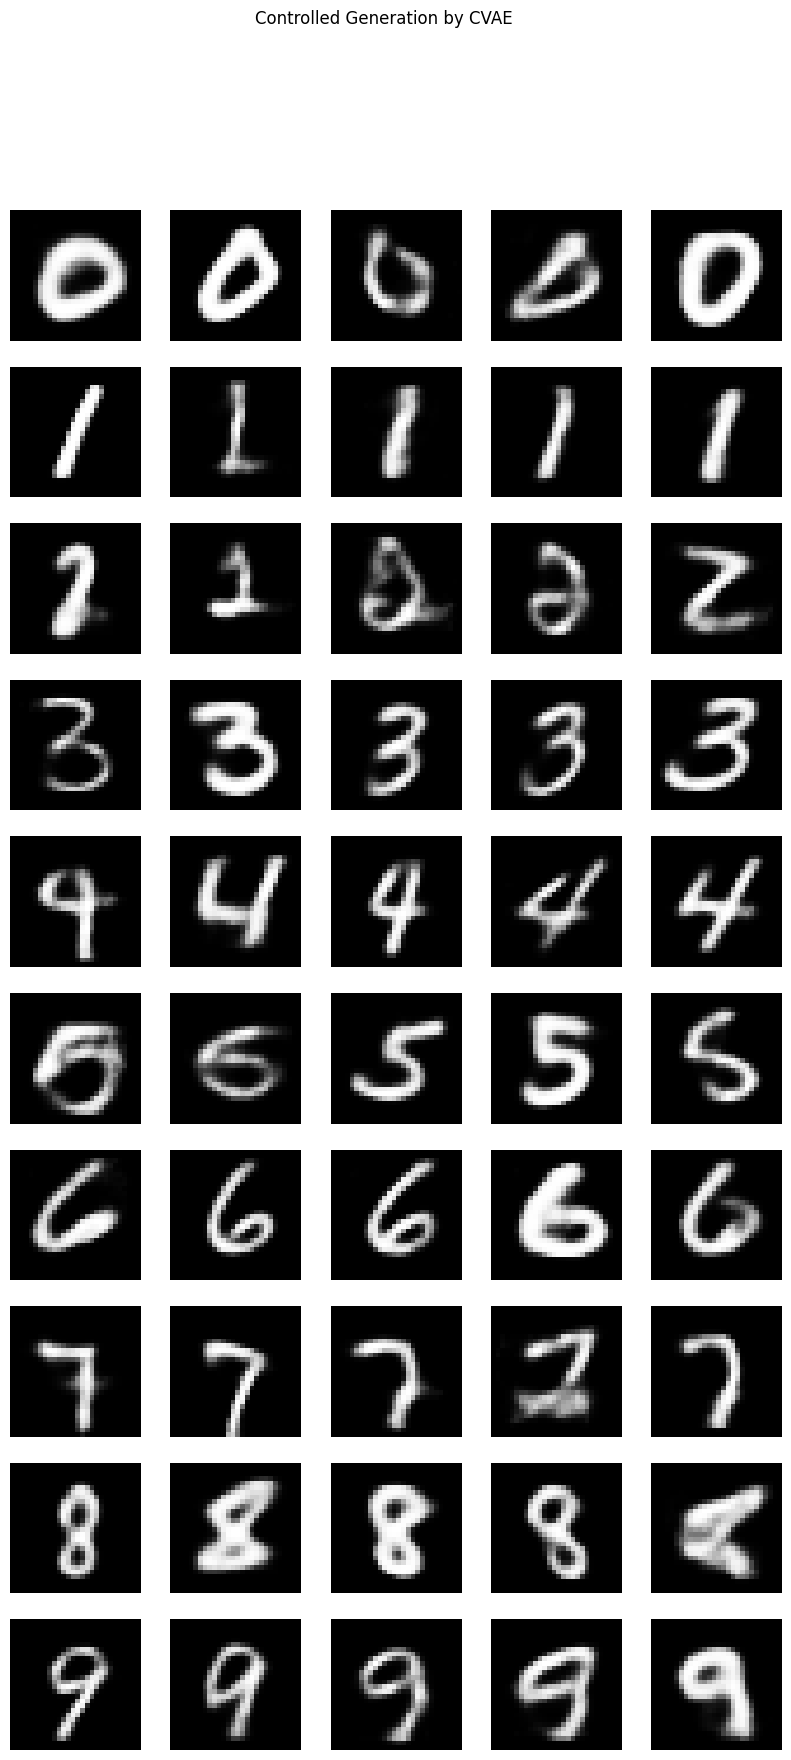

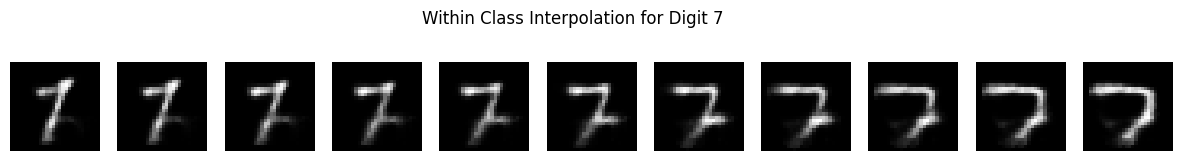

In [18]:
# TODO: Train Conditional VAE
# Remember to pass labels to the model during training

# After training, demonstrate controlled generation:
# 1. Generate samples for each digit class (0-9)
# 2. Show interpolation within a class
# 3. Compare with unconditional VAE
num_epochs = 20
batch_size = 128
learning_rate = 1e-3

model = ConditionalVAE(input_dim=784, hidden_dim=400, latent_dim=20, num_classes=10, beta=1.0).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        x_recon, mu, logvar, loss = model(x, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss/len(train_loader):.4f}")

model.eval()
num_classes = 10
num_samples_per_class = 5

fig, axes = plt.subplots(num_classes, num_samples_per_class, figsize=(num_samples_per_class*2, num_classes*2))

with torch.no_grad():
    for c in range(num_classes):
        y_cond = torch.tensor([c]*num_samples_per_class).to(device)
        z = torch.randn(num_samples_per_class, model.fc_mu.out_features).to(device)
        samples = model.decode(z, y_cond).view(-1, 28, 28).cpu()
        for i in range(num_samples_per_class):
            axes[c, i].imshow(samples[i], cmap='gray')
            axes[c, i].axis('off')
plt.suptitle("Controlled Generation by CVAE")
plt.show()

# class digit 7
digit_class = 7
with torch.no_grad():
    z1, z2 = torch.randn(1, model.fc_mu.out_features).to(device), torch.randn(1, model.fc_mu.out_features).to(device)
    y_cond = torch.tensor([digit_class]).to(device)
    
    alpha_values = torch.linspace(0, 1, 11)
    interpolated_imgs = []
    for alpha in alpha_values:
        z_interp = (1 - alpha) * z1 + alpha * z2
        x_interp = model.decode(z_interp, y_cond).view(28, 28).cpu()
        interpolated_imgs.append(x_interp)
    
    # Plot
    fig, axes = plt.subplots(1, len(alpha_values), figsize=(15, 2))
    for i, img in enumerate(interpolated_imgs):
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')
    plt.suptitle(f"Within Class Interpolation for Digit {digit_class}")
    plt.show()


### Task 3.2: Conditional Interpolation (5 points)

**The Interpolation Playground**: Now that we have a conditional model, we can explore interpolation in multiple dimensions! This is like mixing colors - we can control both the "hue" (class) and "brightness" (style).

**Three Types of Interpolation**:

**1. Latent Interpolation (Style Mixing)**
Fix class $y$, interpolate $z$:
$$z(\alpha) = (1-\alpha)z_1 + \alpha z_2, \quad x(\alpha) = g_\theta(z(\alpha), y)$$

**Result**: Smooth transition between two styles of the same digit
- Example: Thick "7" → Thin "7"
- Application: Creating style variations of the same character

**2. Label Interpolation (Class Morphing)**
Fix $z$, interpolate class labels:
$$y(\alpha) = (1-\alpha)y_1 + \alpha y_2, \quad x(\alpha) = g_\theta(z, y(\alpha))$$

**Mathematical Note**: For one-hot labels, we interpolate in the probability simplex:
$$y(\alpha) = \text{softmax}((1-\alpha)\log(y_1) + \alpha\log(y_2))$$

Or simply use linear interpolation and renormalize.

**Result**: Morphing between two digit classes while preserving style
- Example: "7" → "1" (both are mostly vertical lines)
- Application: Exploring class relationships in the model's understanding

**3. Simultaneous Interpolation (Full Control)**
Interpolate both:
$$z(\alpha) = (1-\alpha)z_1 + \alpha z_2$$
$$y(\alpha) = (1-\alpha)y_1 + \alpha y_2$$
$$x(\alpha) = g_\theta(z(\alpha), y(\alpha))$$

**Result**: Complex morphing that changes both style and class
- Application: Creating smooth transitions in generative animations

**Visualization Strategy**:
Create side-by-side comparisons:
- Row 1: Latent interpolation (class fixed)
- Row 2: Label interpolation (latent fixed)  
- Row 3: Simultaneous interpolation

**Interesting Observations**:
- Which digit pairs morph smoothly? (e.g., 3↔8, 6↔9, 0↔8)
- Which pairs have abrupt transitions? (e.g., 1↔7 might be smoother than 1↔0)
- This reveals the model's learned "digit similarity"!

**Real-World Analogy**: 
Think of it like a 2D control panel:
- X-axis: Style (latent $z$)
- Y-axis: Class (label $y$)
- Each point $(z,y)$ generates a unique digit!

**Fun Experiment**: 
Try interpolating 0 → 8 → 9 → 6. Do you see a "circular" path in digit space? This would indicate the model has learned geometric relationships between digits!


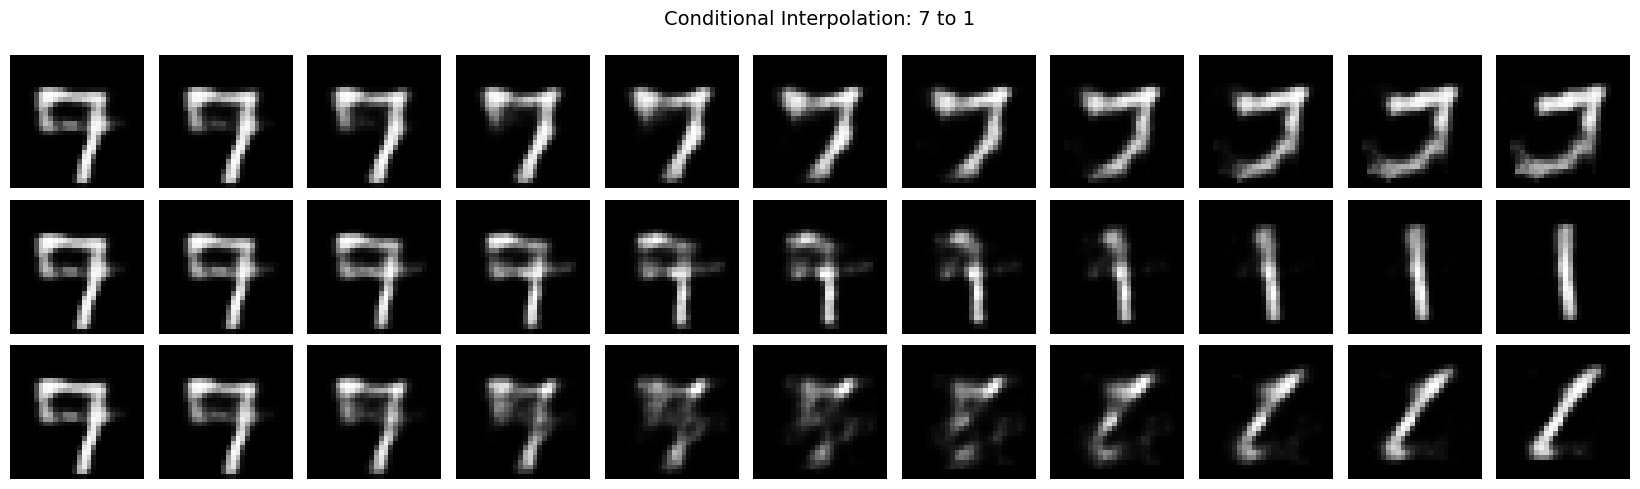

In [20]:
# TODO: Implement conditional interpolation visualizations
# Create side-by-side comparisons of different interpolation strategies

import torch.nn.functional as F

def conditional_interpolation(model, device, class1=7, class2=1, num_steps=11):

    model.eval()
    latent_dim = model.fc_mu.out_features
    alphas = torch.linspace(0, 1, num_steps)

    z1 = torch.randn(1, latent_dim).to(device)
    z2 = torch.randn(1, latent_dim).to(device)

    y1 = F.one_hot(torch.tensor([class1]), num_classes=10).float().to(device)
    y2 = F.one_hot(torch.tensor([class2]), num_classes=10).float().to(device)

    latent_imgs = []
    label_imgs = []
    both_imgs = []

    with torch.no_grad():
        for alpha in alphas:
            #Latent interpolation
            z_latent = (1 - alpha) * z1 + alpha * z2
            x_latent = model.decode(z_latent, torch.tensor([class1]).to(device))
            latent_imgs.append(x_latent.view(28, 28).cpu())

            #Label interpolation
            y_interp = (1 - alpha) * y1 + alpha * y2
            y_interp = y_interp / y_interp.sum(dim=1, keepdim=True)  
            x_label = model.decoder(torch.cat([z1, y_interp], dim=1))
            label_imgs.append(x_label.view(28, 28).cpu())

            #Both interpolated
            z_both = (1 - alpha) * z1 + alpha * z2
            y_both = (1 - alpha) * y1 + alpha * y2
            y_both = y_both / y_both.sum(dim=1, keepdim=True)
            x_both = model.decoder(torch.cat([z_both, y_both], dim=1))
            both_imgs.append(x_both.view(28, 28).cpu())

    fig, axes = plt.subplots(3, num_steps, figsize=(num_steps * 1.5, 5))
    for i in range(num_steps):
        axes[0, i].imshow(latent_imgs[i], cmap='gray')
        axes[0, i].axis('off')

        axes[1, i].imshow(label_imgs[i], cmap='gray')
        axes[1, i].axis('off')

        axes[2, i].imshow(both_imgs[i], cmap='gray')
        axes[2, i].axis('off')

    axes[0, 0].set_ylabel("Latent\n(z)", fontsize=12)
    axes[1, 0].set_ylabel("Label\n(y)", fontsize=12)
    axes[2, 0].set_ylabel("Both\n(z+y)", fontsize=12)

    plt.suptitle(f"Conditional Interpolation: {class1} to {class2}", fontsize=14)
    plt.tight_layout()
    plt.show()

    
conditional_interpolation(model=model,device=device,class1=7,class2=1,num_steps=11)



Latent interpolation (style only) shows that when we change the latent vector while keeping the class fixed, the digit remains the same but its style changes smoothly.This means the latent variable z successfully captures style-related features rather than class identity.

Label interpolation (class only) demonstrates that when we interpolate between two class labels while keeping the latent vector fixed, the generated digit gradually changes from one digit to another. This indicates that the model has learned a continuous representation of digit classe.

Simultaneous interpolation (style and class) shows both the digit identity and its style change at the same time. This confirms that the CVAE can independently control what digit is generated (class) and how it is written (style).

## Part 4: VAE for Anomaly Detection (25 points)

**The Anomaly Detection Challenge**: How do you find a needle in a haystack? Or more precisely, how do you detect fraud, defects, or outliers when you have lots of normal data but very few anomalies?

**Why VAEs Work for Anomaly Detection**:

**The Core Idea**: A VAE trained only on normal data learns to reconstruct normal patterns well. Anomalies, being different from normal patterns, will have high reconstruction error!

**Mathematical Justification**:

If the VAE models normal data distribution $p_{normal}(x)$ well, then:
- Normal $x_{normal}$: $p(x_{normal}|z)$ is high → low reconstruction error
- Anomalous $x_{anomaly}$: $p(x_{anomaly}|z)$ is low → high reconstruction error

**Anomaly Score Options**:

1. **Reconstruction Error** (most common):
   $$s_{recon}(x) = ||x - \hat{x}||^2 = ||x - g_\theta(\mu_\phi(x))||^2$$
   
   Or for binary data:
   $$s_{recon}(x) = -\log p(x|\hat{x}) = -\sum_i [x_i \log \hat{x}_i + (1-x_i)\log(1-\hat{x}_i)]$$

2. **KL Divergence** (latent space deviation):
   $$s_{KL}(x) = D_{KL}(q(z|x) || p(z))$$
   
   High KL means the latent code is far from the prior - unusual!

3. **Combined Score** (often best):
   $$s(x) = \alpha \cdot s_{recon}(x) + (1-\alpha) \cdot s_{KL}(x)$$

4. **Likelihood Estimate** (theoretical best, but harder):
   $$s_{likelihood}(x) = -\log p(x) \approx -\text{ELBO}(x)$$

### Task 4.1: Implement Anomaly Detection using Reconstruction Error (15 points)

**Experimental Setup**:

1. **Training Phase**:
   - Train VAE ONLY on normal classes: digits 0-8
   - The model learns: "What do normal digits look like?"
   - Use standard VAE training procedure

2. **Testing Phase**:
   - Test on two sets:
     - **Normal test set**: Digits 0-8 from test split (should have low scores)
     - **Anomalous test set**: Digit 9 from test split (should have high scores)

3. **Anomaly Score Computation**:
   ```python
   def compute_anomaly_score(model, x):
       # Encode and decode
       mu, logvar = model.encode(x)
       z = model.reparameterize(mu, logvar)
       x_recon = model.decode(z)
       
       # Reconstruction error (per sample)
       recon_error = F.mse_loss(x_recon, x, reduction='none').sum(dim=1)
       
       # Optional: Add KL divergence
       kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)
       
       return recon_error  # or recon_error + beta * kl
   ```

4. **Evaluation Metrics**:

   **ROC Curve**: Plot True Positive Rate vs. False Positive Rate as threshold varies
   - TPR = P(score > threshold | anomaly)
   - FPR = P(score > threshold | normal)
   - **AUC**: Area under ROC curve (higher is better, max = 1.0)

   **Precision-Recall Curve**: Often better for imbalanced problems
   - Precision = TP / (TP + FP)
   - Recall = TP / (TP + FN) = TPR

   **Optimal Threshold**: Maximize F1 score:
   $$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

**Key Design Decisions**:

1. **Which Score?**
   - Start with reconstruction error (simplest)
   - Try adding KL term: $s = s_{recon} + \lambda \cdot s_{KL}$
   - Compare performance!

2. **Threshold Selection**:
   - Can use percentiles: threshold = 95th percentile of normal scores
   - Or optimize F1 on validation set
   - Or use Youden's J statistic: max(TPR - FPR)

3. **β Parameter Effect**:
   - Lower β: Model may overfit to normal data → better anomaly detection?
   - Higher β: Stronger regularization → may generalize worse to anomalies?
   - Experiment with β ∈ {0.5, 1.0, 2.0} and see which works best!

**Expected Results**:
- Good model: AUC > 0.85 (anomalies clearly separable)
- Perfect model: AUC ≈ 1.0 (complete separation)
- Poor model: AUC ≈ 0.5 (random guessing)

**Why Digit 9 as Anomaly?**
Digit 9 is structurally similar to 6 (both have loops), so this is a **challenging** anomaly detection task! The model must learn fine-grained distinctions.

**Advanced: Multi-Class Anomaly Detection**
Instead of one anomaly class, try leaving out multiple classes. How does performance degrade as you remove more normal classes?

**Real-World Insight**: In production, you often don't know what anomalies look like. The VAE approach is **unsupervised** - it only needs normal data for training!


In [21]:
# TODO: Anomaly detection setup
# 1. Create training set with only normal classes (0-8)
# 2. Train VAE on normal data only
# 3. Create test set with both normal (0-8) and anomalous (9) samples

# Load data and filter
all_train = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
all_test = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

# TODO: Filter normal and anomalous samples
normal_train = [(x, y) for x, y in all_train if y != 9]
normal_test = [(x, y) for x, y in all_test if y != 9]
anomalous_test = [(x, y) for x, y in all_test if y == 9]

# TODO: Train VAE on normal data only
batch_size = 128

normal_train_loader = DataLoader(normal_train, batch_size=batch_size, shuffle=True)
normal_test_loader = DataLoader(normal_test, batch_size=batch_size, shuffle=False)
anomalous_test_loader = DataLoader(anomalous_test, batch_size=batch_size, shuffle=False)

model = VAE(input_dim=784, hidden_dim=400, latent_dim=20, beta=1.0).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 20
for epoch in range(num_epochs):
    train_loss, _, _ = train_epoch(model, normal_train_loader, optimizer, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f}")



Epoch 1/20 - Train Loss: 180.8309
Epoch 2/20 - Train Loss: 129.9942
Epoch 3/20 - Train Loss: 118.7461
Epoch 4/20 - Train Loss: 113.9802
Epoch 5/20 - Train Loss: 111.1364
Epoch 6/20 - Train Loss: 109.1438
Epoch 7/20 - Train Loss: 107.6689
Epoch 8/20 - Train Loss: 106.5798
Epoch 9/20 - Train Loss: 105.5827
Epoch 10/20 - Train Loss: 104.7559
Epoch 11/20 - Train Loss: 103.9797
Epoch 12/20 - Train Loss: 103.3755
Epoch 13/20 - Train Loss: 102.8084
Epoch 14/20 - Train Loss: 102.2969
Epoch 15/20 - Train Loss: 101.9301
Epoch 16/20 - Train Loss: 101.5870
Epoch 17/20 - Train Loss: 101.2216
Epoch 18/20 - Train Loss: 100.9818
Epoch 19/20 - Train Loss: 100.7236
Epoch 20/20 - Train Loss: 100.4834


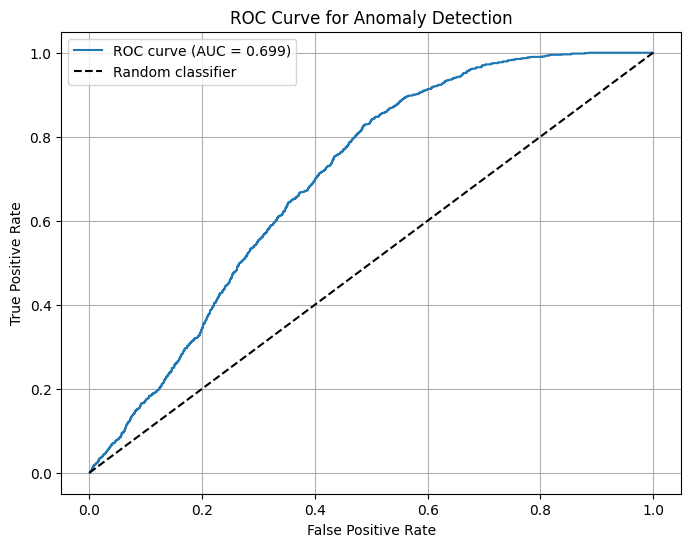

Best F1 score: 0.269
Optimal threshold: 11.775


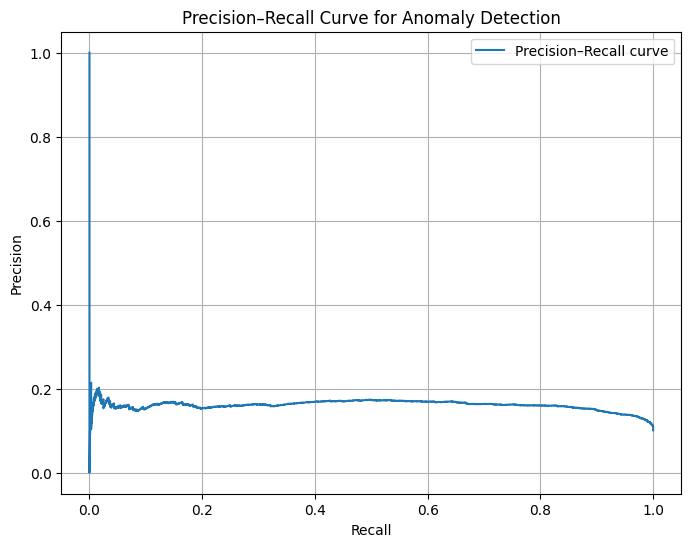

In [30]:
# TODO: Implement anomaly detection evaluation
def compute_anomaly_scores(model, dataloader, device, use_kl=False):
    """
    Compute anomaly scores for a dataset.
    
    Args:
        model: Trained VAE model
        dataloader: DataLoader with images
        device: Device to run on
        use_kl: If True, also include KL divergence in score
    
    Returns:
        Array of anomaly scores
    """
    model.eval()
    scores = []
    
    with torch.no_grad():
        # TODO: For each batch:
        # 1. Reconstruct images
        # 2. Compute reconstruction error (MSE or BCE)
        # 3. Optionally add KL divergence
        # 4. Store scores
        for x, _ in dataloader:
            x = x.to(device)
            x = x.view(x.size(0), -1)

            mu, logvar = model.encode(x)
            z = model.reparameterize(mu, logvar)
            x_recon = model.decode(z)

            recon_error = F.mse_loss(x_recon, x, reduction='none').sum(dim=1)

            if use_kl:
                kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)
                score = recon_error + kl
            else:
                score = recon_error

            scores.append(score.cpu().numpy())
    
    return np.concatenate(scores)

# TODO: Compute scores for normal and anomalous test sets

x_test_all = []
labels_all = []

for x, y in test_loader:
    labels_all.append((y == 9).int())
    x_test_all.append(x)

x_test_all = torch.cat(x_test_all)   
labels_all = torch.cat(labels_all).numpy() 

normal_scores = compute_anomaly_scores(model, normal_test_loader, device)
anomalous_scores = compute_anomaly_scores(model, anomalous_test_loader, device)

# TODO: Create labels (0 for normal, 1 for anomalous)
# Combine scores and labels
all_scores = np.concatenate([normal_scores, anomalous_scores])
all_labels = np.concatenate([np.zeros(len(normal_scores)),np.ones(len(anomalous_scores))])

# TODO: Compute ROC curve and AUC
from sklearn.metrics import roc_curve, auc, roc_auc_score

fpr, tpr, thresholds = roc_curve(all_labels, all_scores)
roc_auc = roc_auc_score(all_labels, all_scores)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Anomaly Detection')
plt.legend()
plt.grid(True)
plt.show()

# TODO: Find optimal threshold (e.g., maximize F1 score)
from sklearn.metrics import f1_score, precision_recall_curve

precision, recall, pr_thresholds = precision_recall_curve(all_labels, all_scores)

f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = pr_thresholds[best_idx]

print(f"Best F1 score: {f1_scores[best_idx]:.3f}")
print(f"Optimal threshold: {best_threshold:.3f}")

# TODO: Compute precision-recall curve and find best threshold
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label='Precision–Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve for Anomaly Detection')
plt.grid(True)
plt.legend()
plt.show()


**The ROC AUC of 0.699 indicates that the reconstruction error provides a moderate ability to distinguish anomalous digit 9 from normal digits (0–8). While better than random guessing, the separation is not perfect.**

**The best F1 score of 0.269 is relatively low, which is expected in this setting. Digit 9 shares visual similarities with several normal digits, allowing the VAE to partially reconstruct it despite never seeing it during training.**

### Task 4.2: Visualize Anomalies and Reconstructions (10 points)

**Visual Storytelling**: A picture is worth a thousand words! Visualizations help us understand what the model is doing and diagnose issues.

**Visualization 1: Reconstruction Comparison**

Create side-by-side displays:
```
Normal Samples:
Original | Reconstruction | Error Map

Anomalous Samples:
Original | Reconstruction | Error Map
```

**Error Map**: Visualize $|x - \hat{x}|$ as an image to see WHERE the model struggles.

**Expected Observations**:
- Normal digits: Clean reconstructions, low error
- Anomalies: Blurry/incorrect reconstructions, high error concentrated in distinctive regions

**Visualization 2: Score Distributions**

Create histograms of anomaly scores:
- Overlay: Normal scores (blue) vs. Anomalous scores (red)
- Add vertical line: Optimal threshold
- This shows how separable the classes are!

**Mathematical Insight**: If distributions overlap significantly, you'll have many false positives/negatives. If they're well-separated, you can find a threshold with high accuracy.

**Visualization 3: ROC and PR Curves**

- **ROC Curve**: Shows trade-off between TPR and FPR
- **PR Curve**: Better for imbalanced data (shows precision-recall trade-off)
- **AUC values**: Summarize performance in a single number

**Visualization 4: Error Analysis**

Show examples of:
- **False Positives**: Normal digits classified as anomalies
  - Why? Might be unusual styles, noisy, or edge cases
- **False Negatives**: Anomalies classified as normal
  - Why? Digit 9 might look similar to 6, or model learned too general patterns

**Deep Analysis Questions**:

1. **Why Higher Reconstruction Error for Anomalies?**

   **Theoretical Answer**: The VAE's decoder $g_\theta$ was trained to map latent codes to normal data patterns. When given an anomaly:
   - The encoder tries to find the "closest" normal pattern
   - But since anomalies are fundamentally different, the best reconstruction is still poor
   - This manifests as high reconstruction error

   **Visual Evidence**: Anomalies often get reconstructed as their "closest normal neighbor" (e.g., 9 → 6 or 8)

2. **False Positive Analysis**:
   - Look at FP examples: Are they unusual normal digits?
   - Edge cases: Very thin/thick digits, unusual rotations
   - **Solution**: More diverse training data, or adjust threshold

3. **False Negative Analysis**:
   - Look at FN examples: Do they look "normal" to humans too?
   - Similarity to normal classes (9 looks like 6 or 4)
   - **Solution**: More sophisticated features, or ensemble methods

**Performance Improvement Strategies**:

1. **Feature Engineering**:
   - Try different β values
   - Use combined score: $s = \alpha s_{recon} + (1-\alpha) s_{KL}$
   - Try different reconstruction losses (MSE vs. BCE)

2. **Architecture Improvements**:
   - Larger latent dimension (capture more variation)
   - Deeper networks (better feature extraction)
   - Convolutional layers (spatial structure)

3. **Training Improvements**:
   - Data augmentation (more diverse normal examples)
   - Different optimizers/learning rates
   - Ensemble of multiple VAEs

4. **Post-Processing**:
   - Calibrate scores using isotonic regression
   - Use active learning to refine on FP/FN

**Fun Challenge**: 
Try to find the "most normal-looking anomaly" (lowest anomaly score among digit 9s). What makes it look normal? And the "most anomalous normal" (highest score among digits 0-8). What makes it unusual?

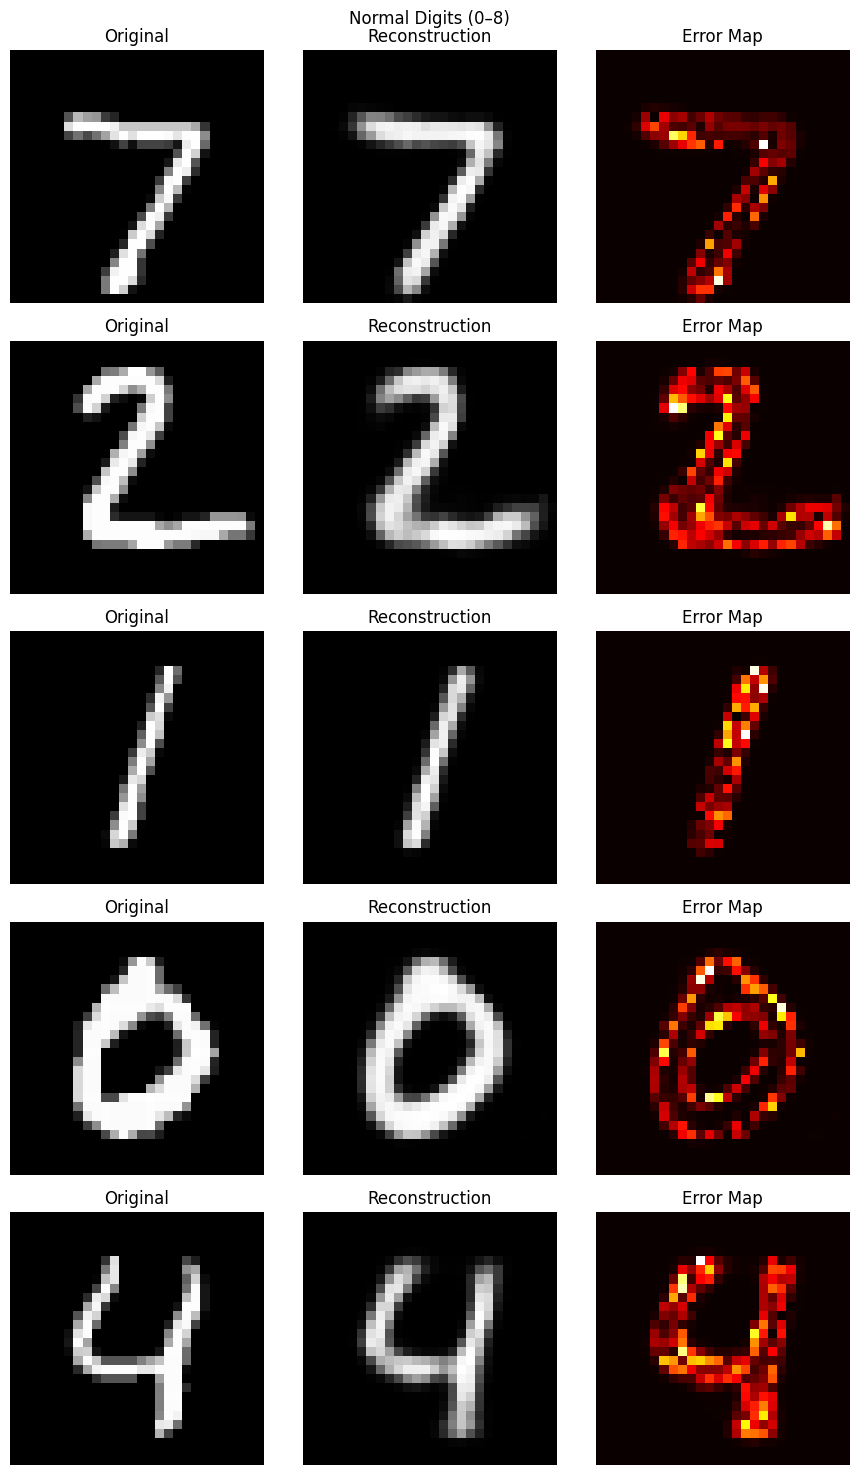

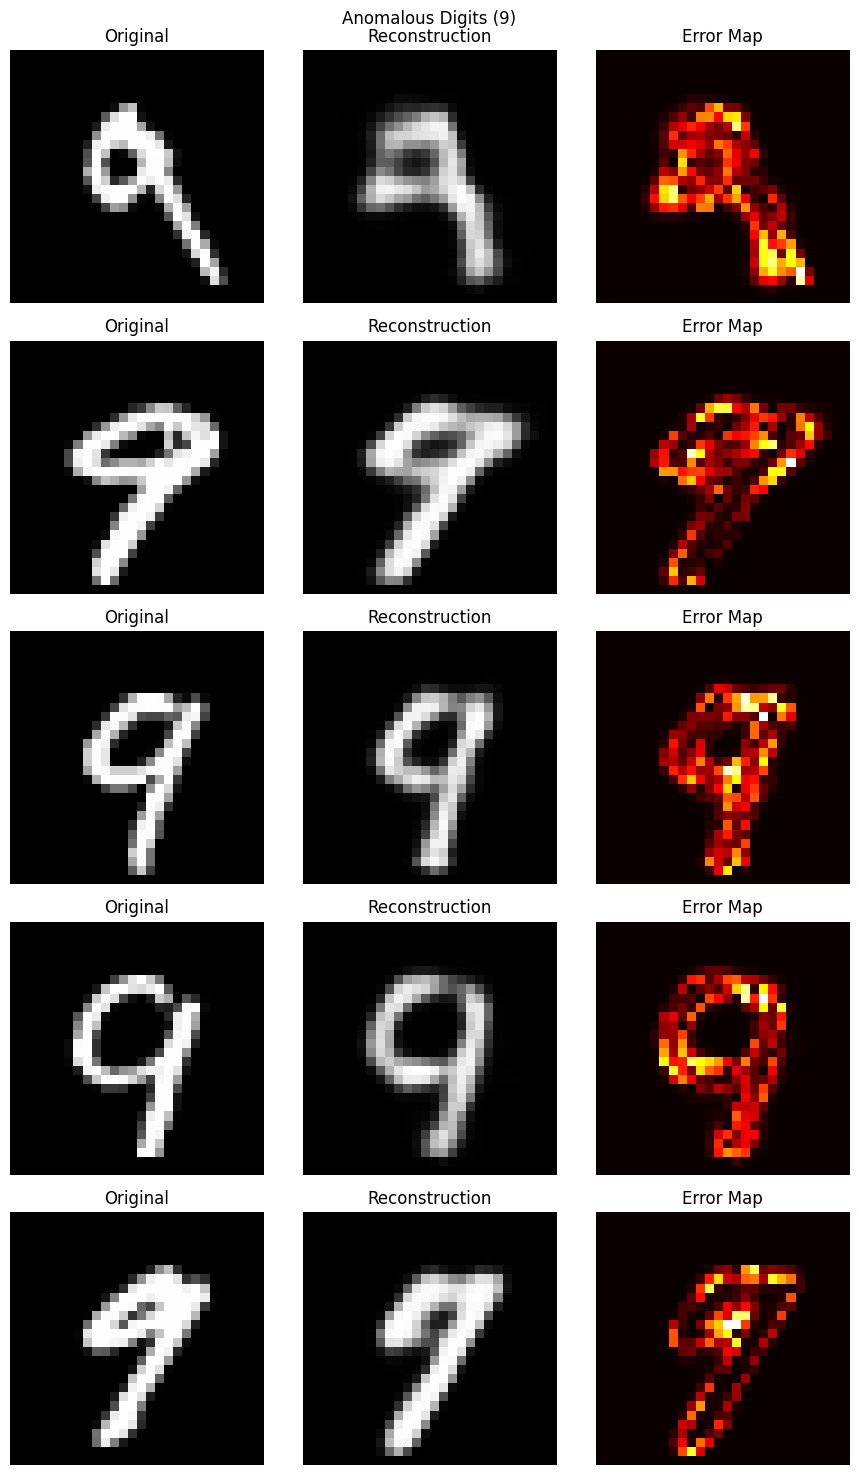

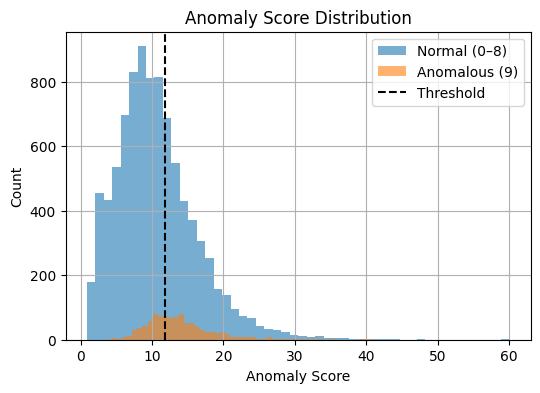

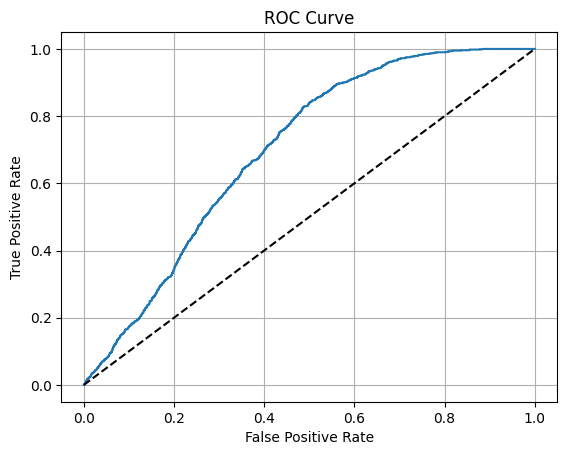

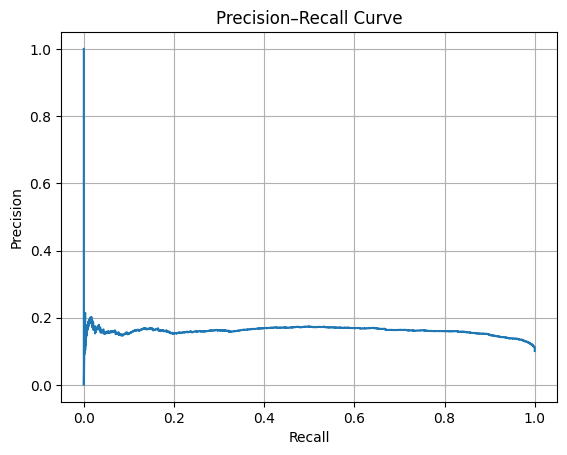

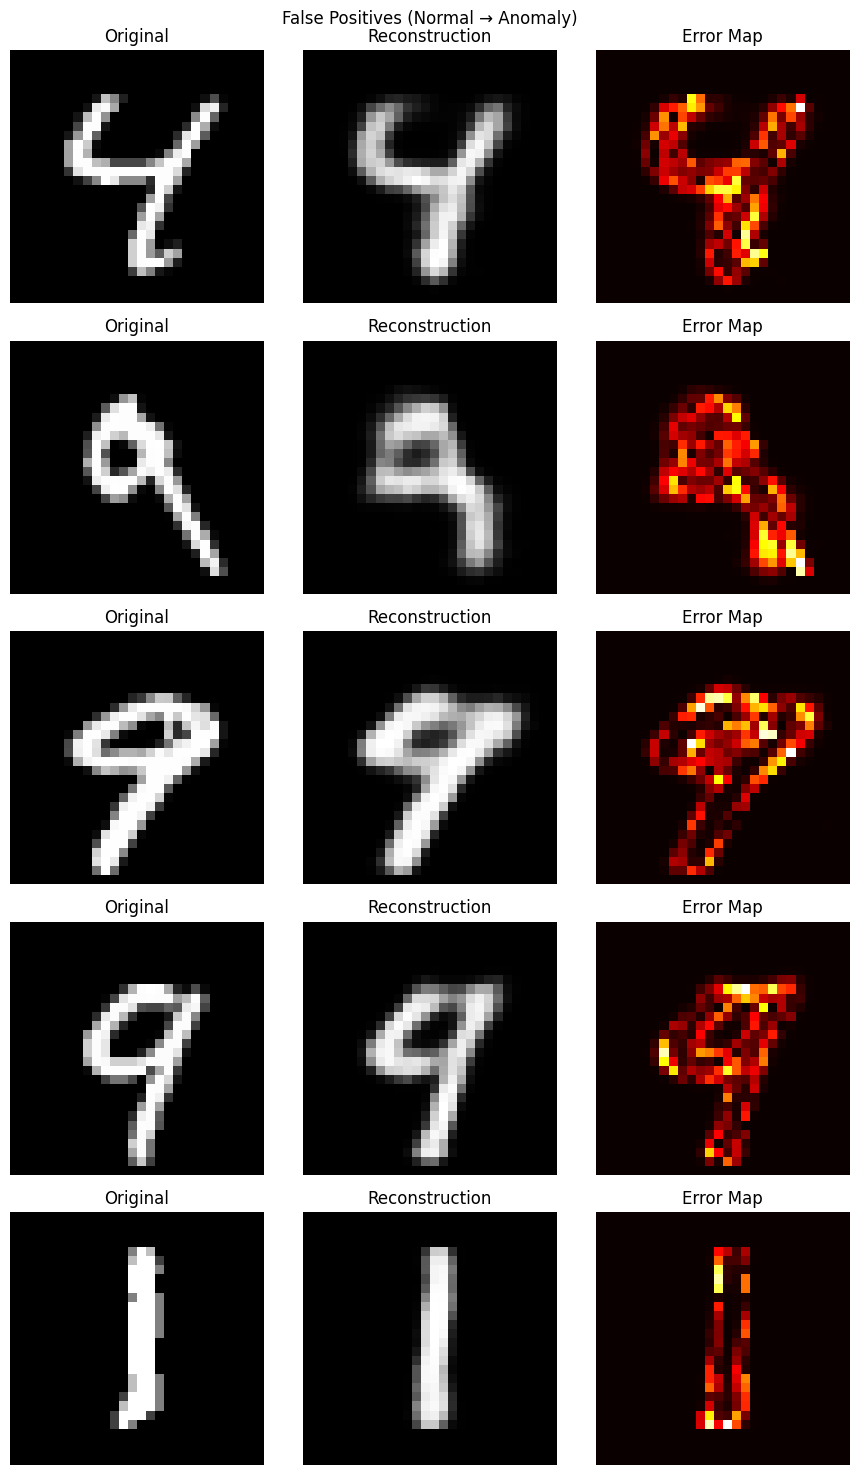

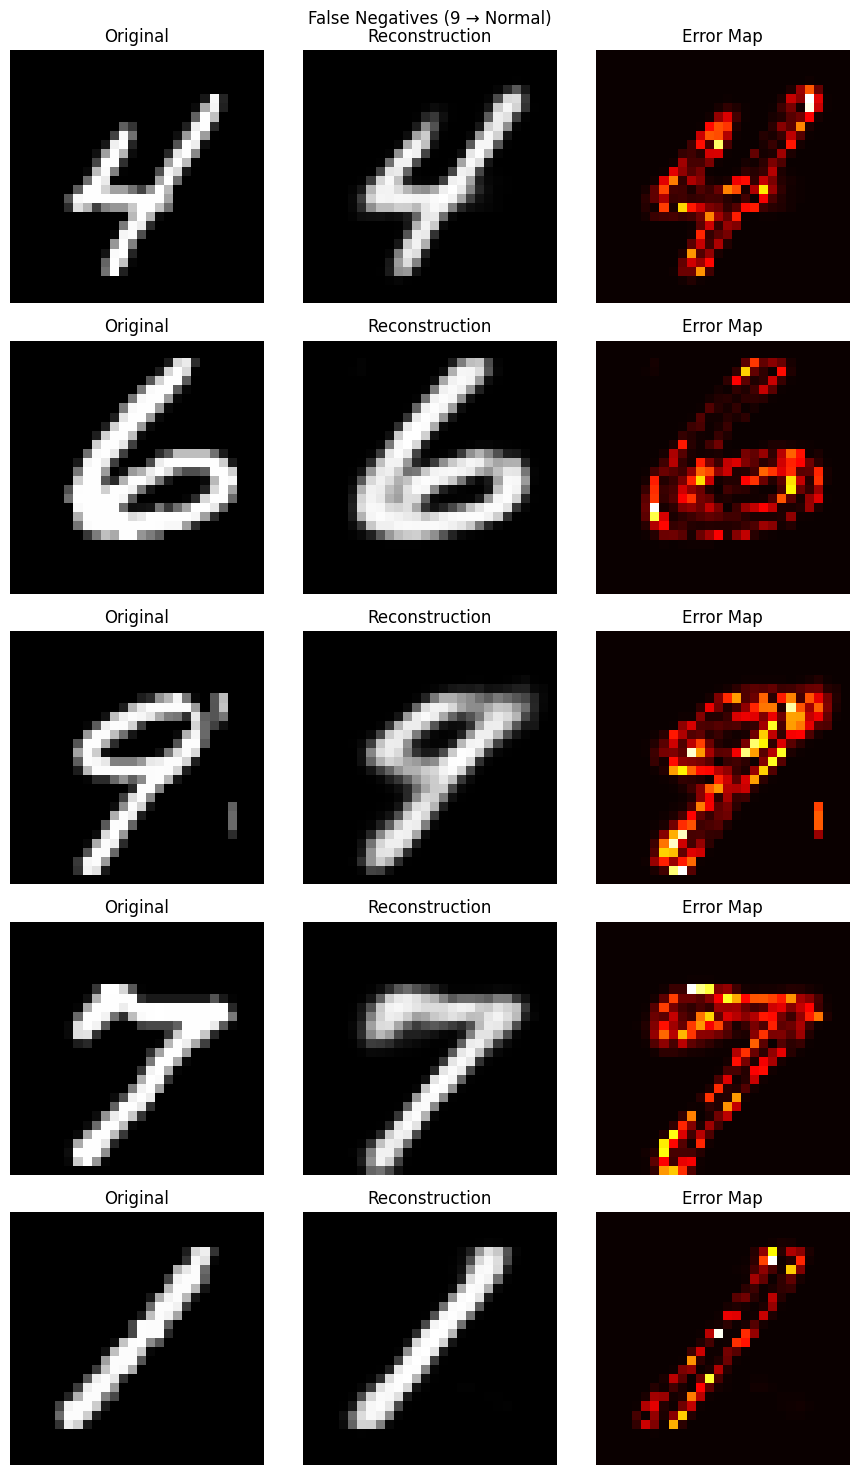

In [31]:
# TODO: Create visualization comparing normal vs anomalous reconstructions
# Show side-by-side: original, reconstruction, and reconstruction error

# 1. Sample some normal test images and their reconstructions
# 2. Sample some anomalous images and their reconstructions
# 3. Visualize reconstruction errors
# 4. Create histogram comparing score distributions

def reconstruct(model, x, device):
    model.eval()
    with torch.no_grad():
        x = x.to(device)
        x_flat = x.view(x.size(0), -1)     
        recon_flat, _, _, _ = model(x_flat) 
        recon = recon_flat.view(-1, 1, 28, 28)
    return recon


def show_reconstructions(model, images, title, device, n=5):
    recon = reconstruct(model, images[:n], device)

    fig, axes = plt.subplots(n, 3, figsize=(9, 3*n))

    for i in range(n):
        x = images[i].cpu().squeeze()
        r = recon[i].cpu().squeeze()
        err = torch.abs(x - r)

        axes[i, 0].imshow(x, cmap='gray')
        axes[i, 0].set_title("Original")

        axes[i, 1].imshow(r, cmap='gray')
        axes[i, 1].set_title("Reconstruction")

        axes[i, 2].imshow(err, cmap='hot')
        axes[i, 2].set_title("Error Map")

        for j in range(3):
            axes[i, j].axis('off')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

for x_norm, _ in normal_test_loader:
    normal_imgs = x_norm
    break

for x_anom, _ in anomalous_test_loader:
    anomalous_imgs = x_anom
    break

show_reconstructions(model, normal_imgs, "Normal Digits (0–8)", device)
show_reconstructions(model, anomalous_imgs, "Anomalous Digits (9)", device)

plt.figure(figsize=(6, 4))
plt.hist(normal_scores, bins=50, alpha=0.6, label="Normal (0–8)")
plt.hist(anomalous_scores, bins=50, alpha=0.6, label="Anomalous (9)")
plt.axvline(best_threshold, color='k', linestyle='--', label="Threshold")
plt.xlabel("Anomaly Score")
plt.ylabel("Count")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.grid(True)
plt.show()

from sklearn.metrics import roc_curve, precision_recall_curve

labels = np.concatenate([
    np.zeros(len(normal_scores)),
    np.ones(len(anomalous_scores))
])

scores = np.concatenate([normal_scores, anomalous_scores])

# ROC
fpr, tpr, _ = roc_curve(labels, scores)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.grid(True)
plt.show()

# Precision–Recall
prec, rec, _ = precision_recall_curve(labels, scores)
plt.figure()
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.grid(True)
plt.show()

preds = (scores > best_threshold).astype(int)

false_pos_idx = np.where((preds == 1) & (labels == 0))[0]
false_neg_idx = np.where((preds == 0) & (labels == 1))[0]


if len(false_pos_idx) > 0:
    show_reconstructions(
        model,
        x_test_all[false_pos_idx][:5],
        "False Positives (Normal → Anomaly)",
        device
    )

if len(false_neg_idx) > 0:
    show_reconstructions(
        model,
        x_test_all[false_neg_idx][:5],
        "False Negatives (9 → Normal)",
        device
    )



Normal digits are reconstructed accurately with low reconstruction error, while digit 9 which the model never saw during training produces blurrier reconstructions with high localized error.

The overlap in score distributions explains the moderate ROC-AUC (0.696) and low F1 score, indicating that some anomalous digits resemble normal ones (like 9 and 6).

False positives often correspond to unusual writing styles or blury images, while false negatives occur when digit 9 closely matches learned normal patterns like number 4,6and7.